In [43]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import matplotlib.lines as mlines
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
import seaborn as sns

In [44]:
# to install the latest release (from PyPI)
!pip install SciencePlots


In [45]:
import scienceplots
plt.style.use(['science','ieee', 'no-latex', 'grid'])


In [46]:
sns.set()
sns.reset_orig()
plt.style.use(['science','ieee', 'no-latex', 'grid'])

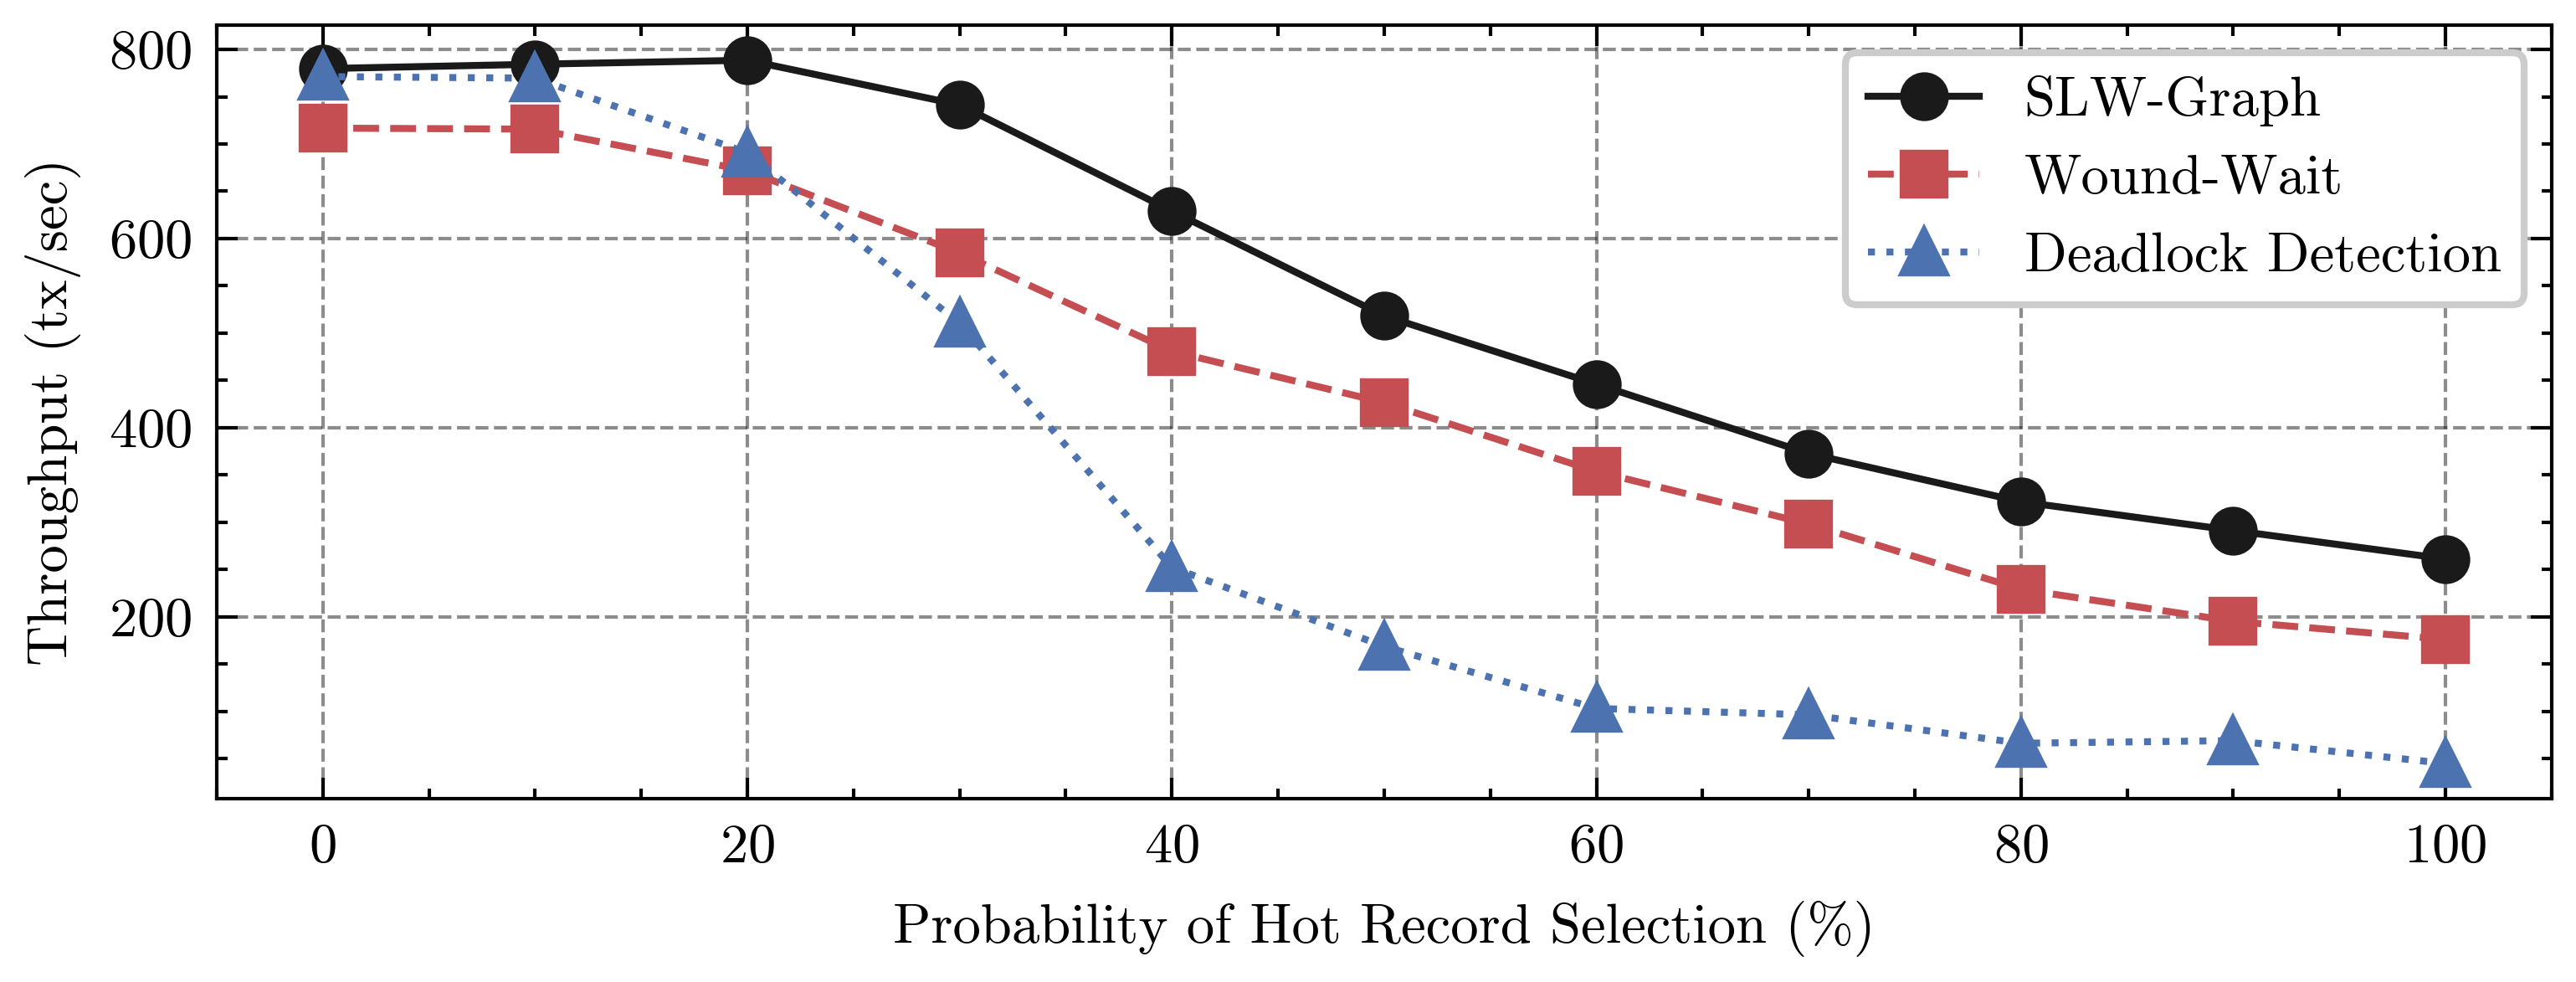

In [47]:


# Data
prob = [100, 90, 80, 70, 60, 50, 40, 30, 20, 10, 0]
slw_32 = [261.3, 291.38, 321.78, 372.73, 446.13, 518.37, 629.15, 741.44, 788.58, 784.35, 779.7]
ww_32 = [176.24, 195.41, 229.21, 298.31, 353.69, 426.6, 480.83, 584.81, 671.83, 715.71, 716.81]
dd_32 = [45.06, 69.17, 66.4, 96.51, 103.22, 168.82, 252.41, 510.42, 690.64, 769.6, 771.28]

# Plotting
plt.figure(figsize=(6, 2))
plt.plot(prob, slw_32, label='SLW-Graph', marker='o')
plt.plot(prob, ww_32, label='Wound-Wait', marker='s')
plt.plot(prob, dd_32, label='Deadlock Detection', marker='^')

# Adding title and labels

plt.xlabel('Probability of Hot Record Selection (%)')
plt.ylabel('Throughput (tx/sec)')
plt.legend()
plt.grid(True)

# Display the plot
# plt.show()
plt.plot()
plt.savefig('slw-result.pdf', bbox_inches='tight')

In [48]:
df = pd.read_csv('store-results.csv')

In [49]:
df.head()

,num of records,mode,operation_delay,hot_records,prob,threads,throughput(tx/s),item_read(tx/s),request_retried,total_retries,...,unlocking_time,committing_time,waiting_for_others_time,rolling_back_time,avg waste,avg lock,avg wait time,avg io,avg commit,avg unlock
0,39272045,slw,0,../rocksdb/hotspots/hot_records_32_items,0,64,667335.81,0,0,0,...,115396386,62776261,0,0,0.033556,34.007904,0.033556,31.604732,1.598497,2.938385
1,38771674,slw,0,../rocksdb/hotspots/hot_records_32_items,10,64,657147.02,0,0,0,...,109037171,65184143,0,0,7.188950,37.954158,7.188950,28.849318,1.681231,2.812289
2,41917691,slw,0,../rocksdb/hotspots/hot_records_32_items,20,64,710469.34,0,0,0,...,96865641,85741325,0,0,20.553415,46.377109,20.553415,23.890036,2.045469,2.310853
3,33535217,slw,0,../rocksdb/hotspots/hot_records_32_items,30,64,568383.87,0,0,0,...,77562703,85135821,0,0,46.882728,75.806358,46.882728,21.417717,2.538699,2.312873
4,14953551,slw,0,../rocksdb/hotspots/hot_records_32_items,40,64,253351.25,0,0,0,...,46230378,67044470,0,0,174.225432,234.761968,174.225432,24.648693,4.483515,3.091599


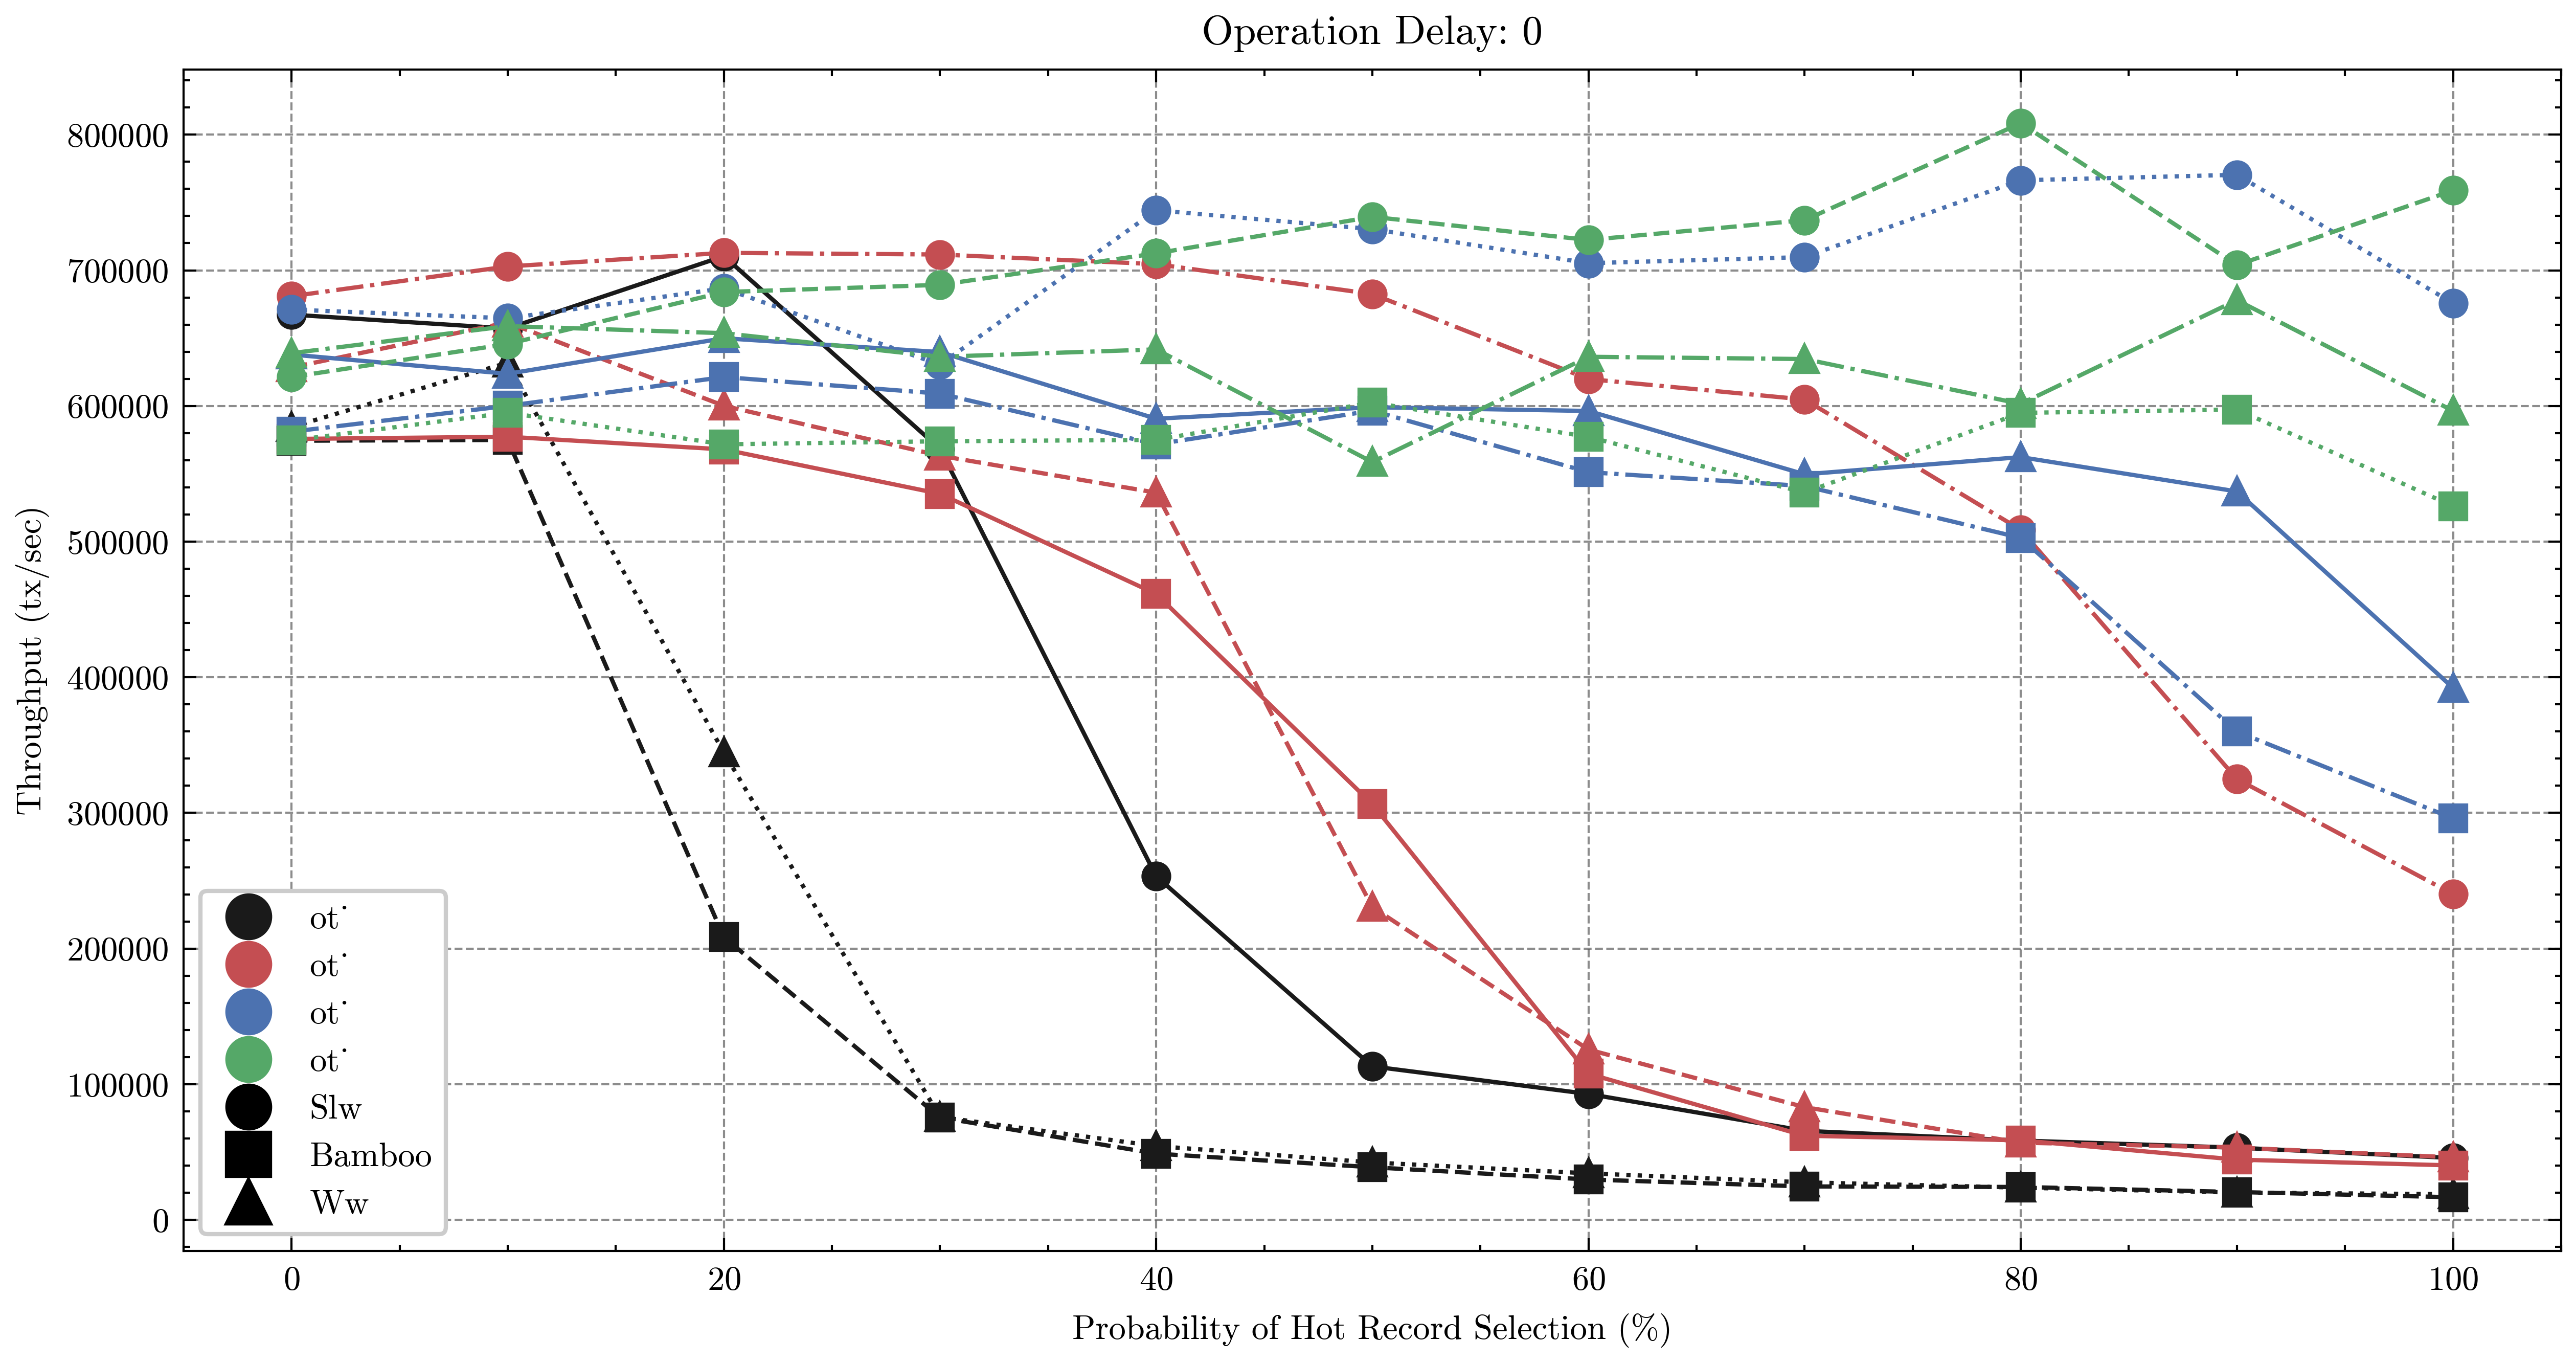

<Figure size 6000x3000 with 0 Axes>

In [50]:
# Get Matplotlib's default color cycle
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Map each hotness level to a specific color from the color cycle
hotness_color_map = {hotness: color for hotness, color in zip(pd.unique(df['hot_records']), colors)}
markers = {
    'slw': 'o',        # Circle for SLW-Graph
    'bamboo': 's',     # Square for Bamboo
    'ww': '^'          # Triangle for Wound-Wait
}

# Determine the number of unique delays
unique_delays = sorted(pd.unique(df['operation_delay']))
num_delays = len(unique_delays)

# Create subplots
fig, axes = plt.subplots(nrows=num_delays, ncols=1, figsize=(10, 5 * num_delays), sharex=True)

# If only one delay, ensure axes is iterable
if num_delays == 1:
    axes = [axes]


for ax, delay in zip(axes, unique_delays):
  plt.figure(figsize=(10, 5))
  for hotness in pd.unique(df['hot_records']):
    filtered_df = df[(df['operation_delay'] == delay) & (df['hot_records'] == hotness)]

    color = hotness_color_map[hotness]

    ax.plot(filtered_df[filtered_df['mode'] == 'slw']['prob'], filtered_df[filtered_df['mode'] == 'slw']['throughput(tx/s)'], label='SLW-Graph', marker=markers['slw'], color=color)
    ax.plot(filtered_df[filtered_df['mode'] == 'slw']['prob'], filtered_df[filtered_df['mode'] == 'bamboo']['throughput(tx/s)'], label='Bamboo', marker=markers['bamboo'], color=color)
    ax.plot(filtered_df[filtered_df['mode'] == 'slw']['prob'], filtered_df[filtered_df['mode'] == 'ww']['throughput(tx/s)'], label='Wound-Wait', marker=markers['ww'], color=color)


    # Custom legend for colors (hotness)
    color_legend = [mlines.Line2D([], [], color=color, marker='o', linestyle='None', markersize=10,
                                  label=hotness[21:24]) for hotness, color in hotness_color_map.items()]

    # Custom legend for markers (types)
    marker_legend = [mlines.Line2D([], [], color='black', marker=marker, linestyle='None', markersize=10,
                                   label=f'{mode.capitalize()}') for mode, marker in markers.items()]
    ax.set_title(f'Operation Delay: {delay}')
    ax.set_xlabel('Probability of Hot Record Selection (%)')
    ax.set_ylabel('Throughput (tx/sec)')
    ax.legend(handles=color_legend + marker_legend, loc='best')
    # plt.legend()
    ax.grid(True)



plt.tight_layout()
plt.show()

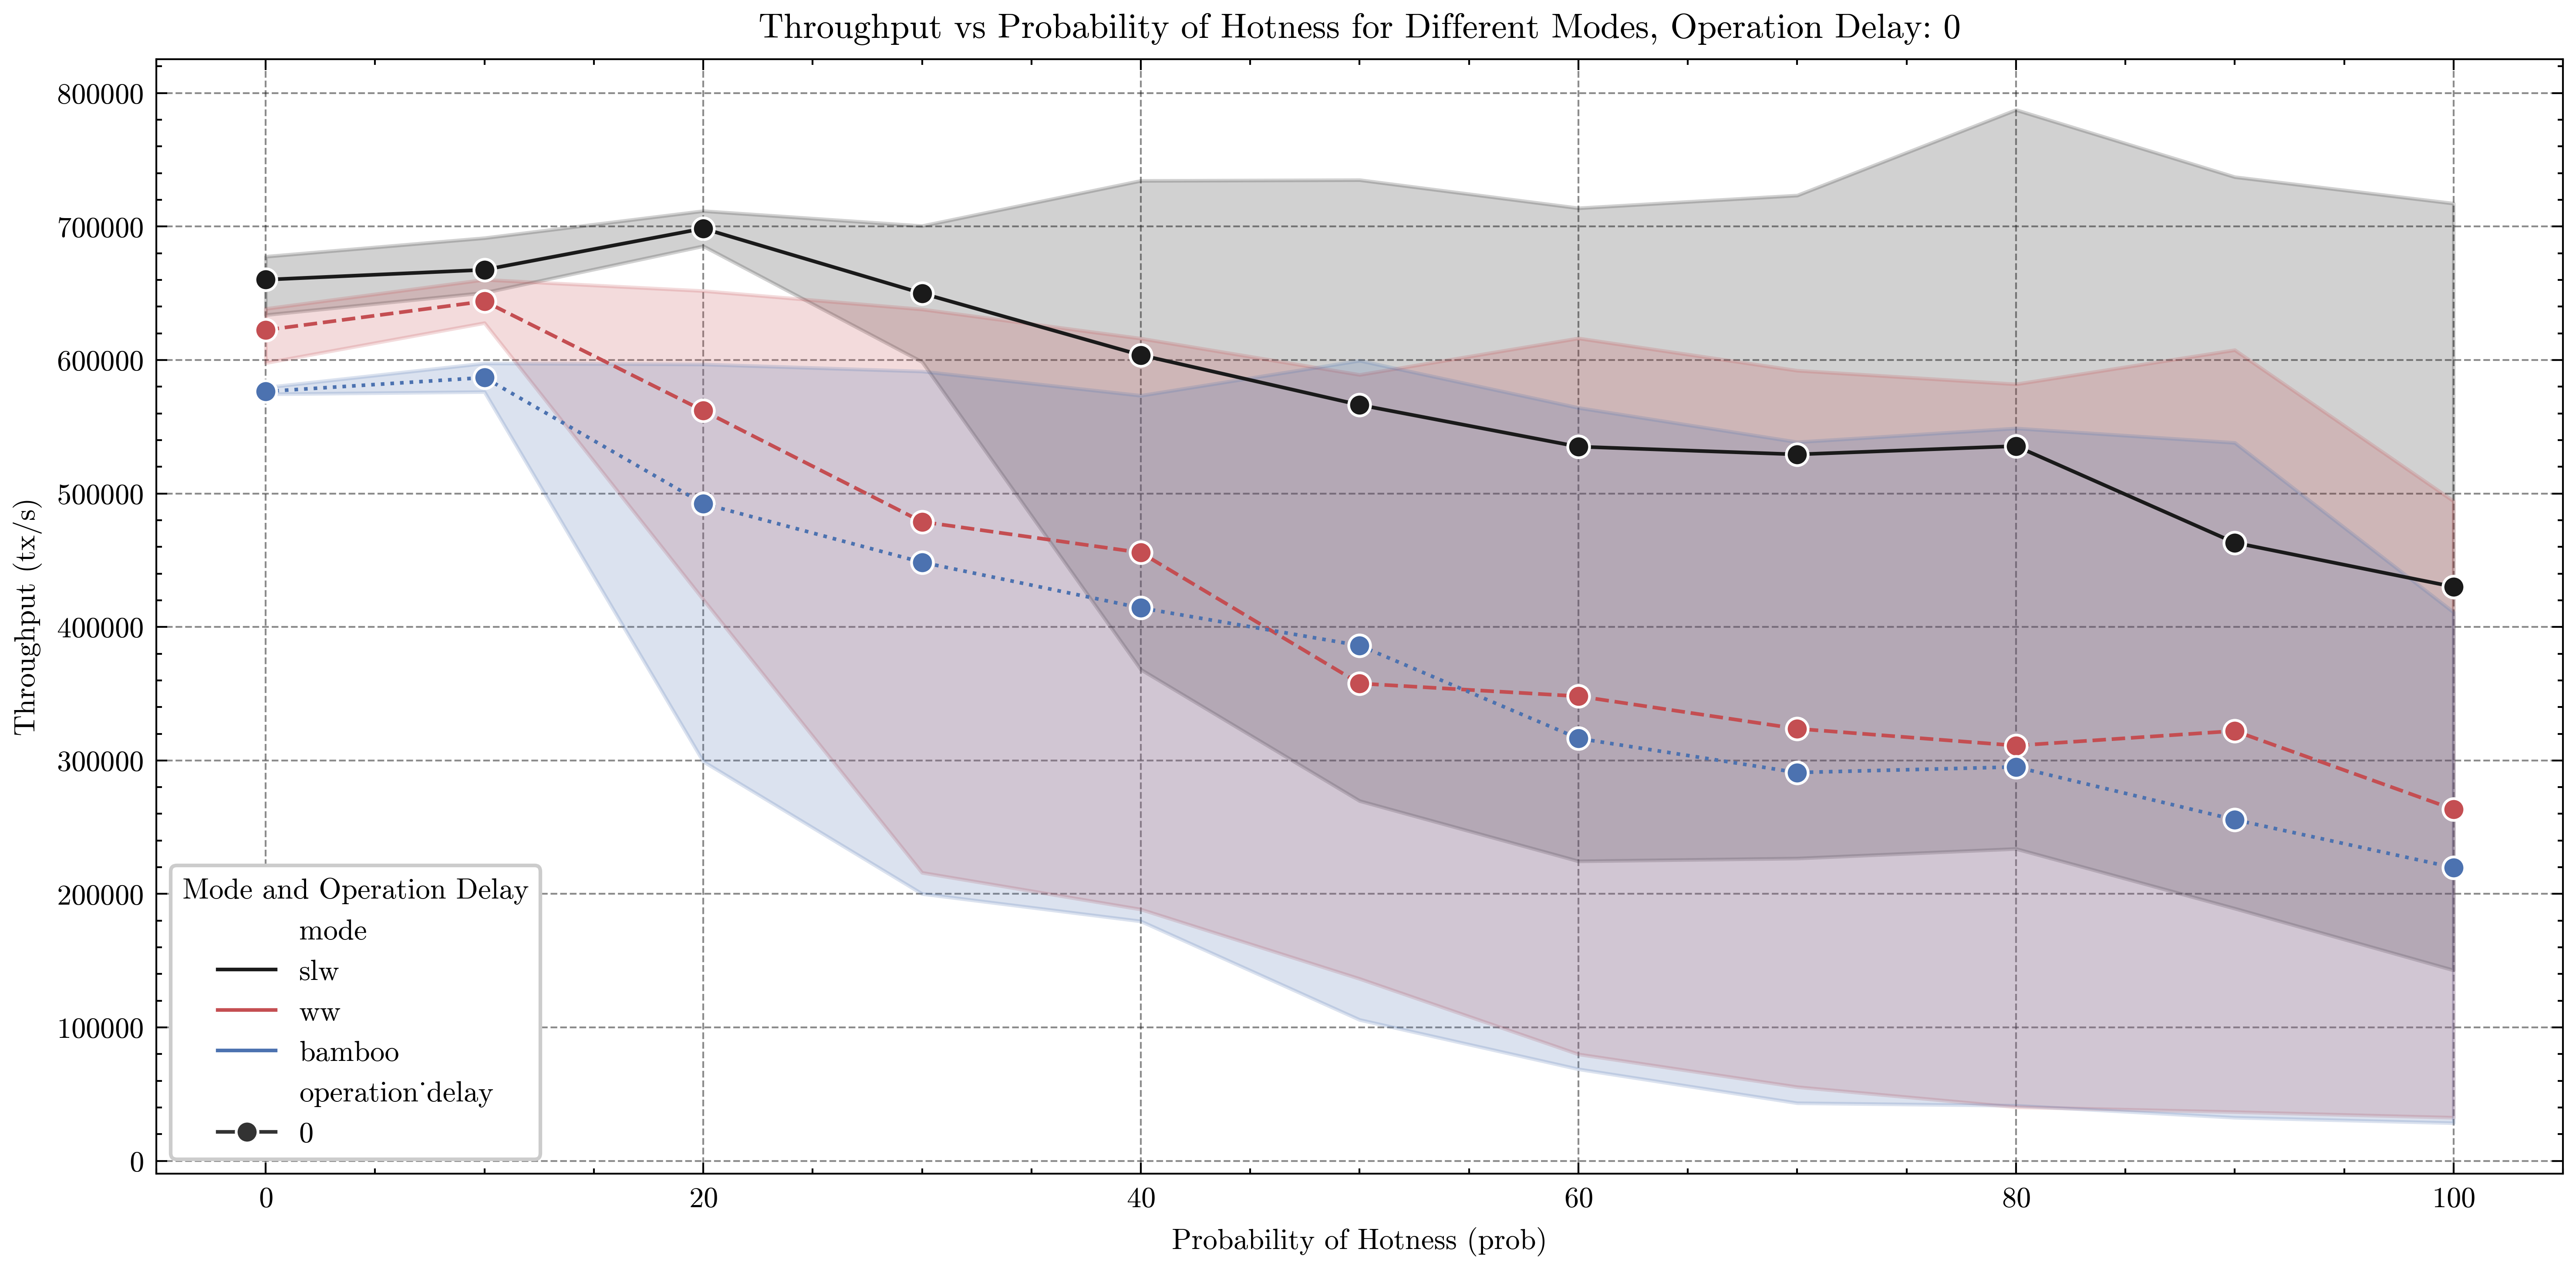

In [51]:
# Get Matplotlib's default color cycle
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Map each hotness level to a specific color from the color cycle
hotness_color_map = {hotness: color for hotness, color in zip(pd.unique(df['hot_records']), colors)}
markers = {
    'slw': 'o',        # Circle for SLW-Graph
    'bamboo': 's',     # Square for Bamboo
    'ww': '^'          # Triangle for Wound-Wait
}

# Determine the number of unique delays
unique_delays = sorted(pd.unique(df['operation_delay']))
num_delays = len(unique_delays)

# # Create subplots
# fig, axes = plt.subplots(nrows=num_delays, ncols=1, figsize=(10, 5 * num_delays), sharex=True)

# # If only one delay, ensure axes is iterable
# if num_delays == 1:
#     axes = [axes]


for ax, delay in zip(axes, unique_delays):
  plt.figure(figsize=(10, 5))
  # for hotness in pd.unique(df['hot_records']):
  filtered_df = df[(df['operation_delay'] == delay)]

  sns.lineplot(data=filtered_df, x='prob', y='throughput(tx/s)', hue='mode', style='operation_delay', markers=True, dashes=False)

  plt.title(f'Throughput vs Probability of Hotness for Different Modes, Operation Delay: {delay}')
  plt.xlabel('Probability of Hotness (prob)')
  plt.ylabel('Throughput (tx/s)')
  plt.legend(title='Mode and Operation Delay')
  plt.grid(True)



plt.tight_layout()
plt.show()

## Performance store


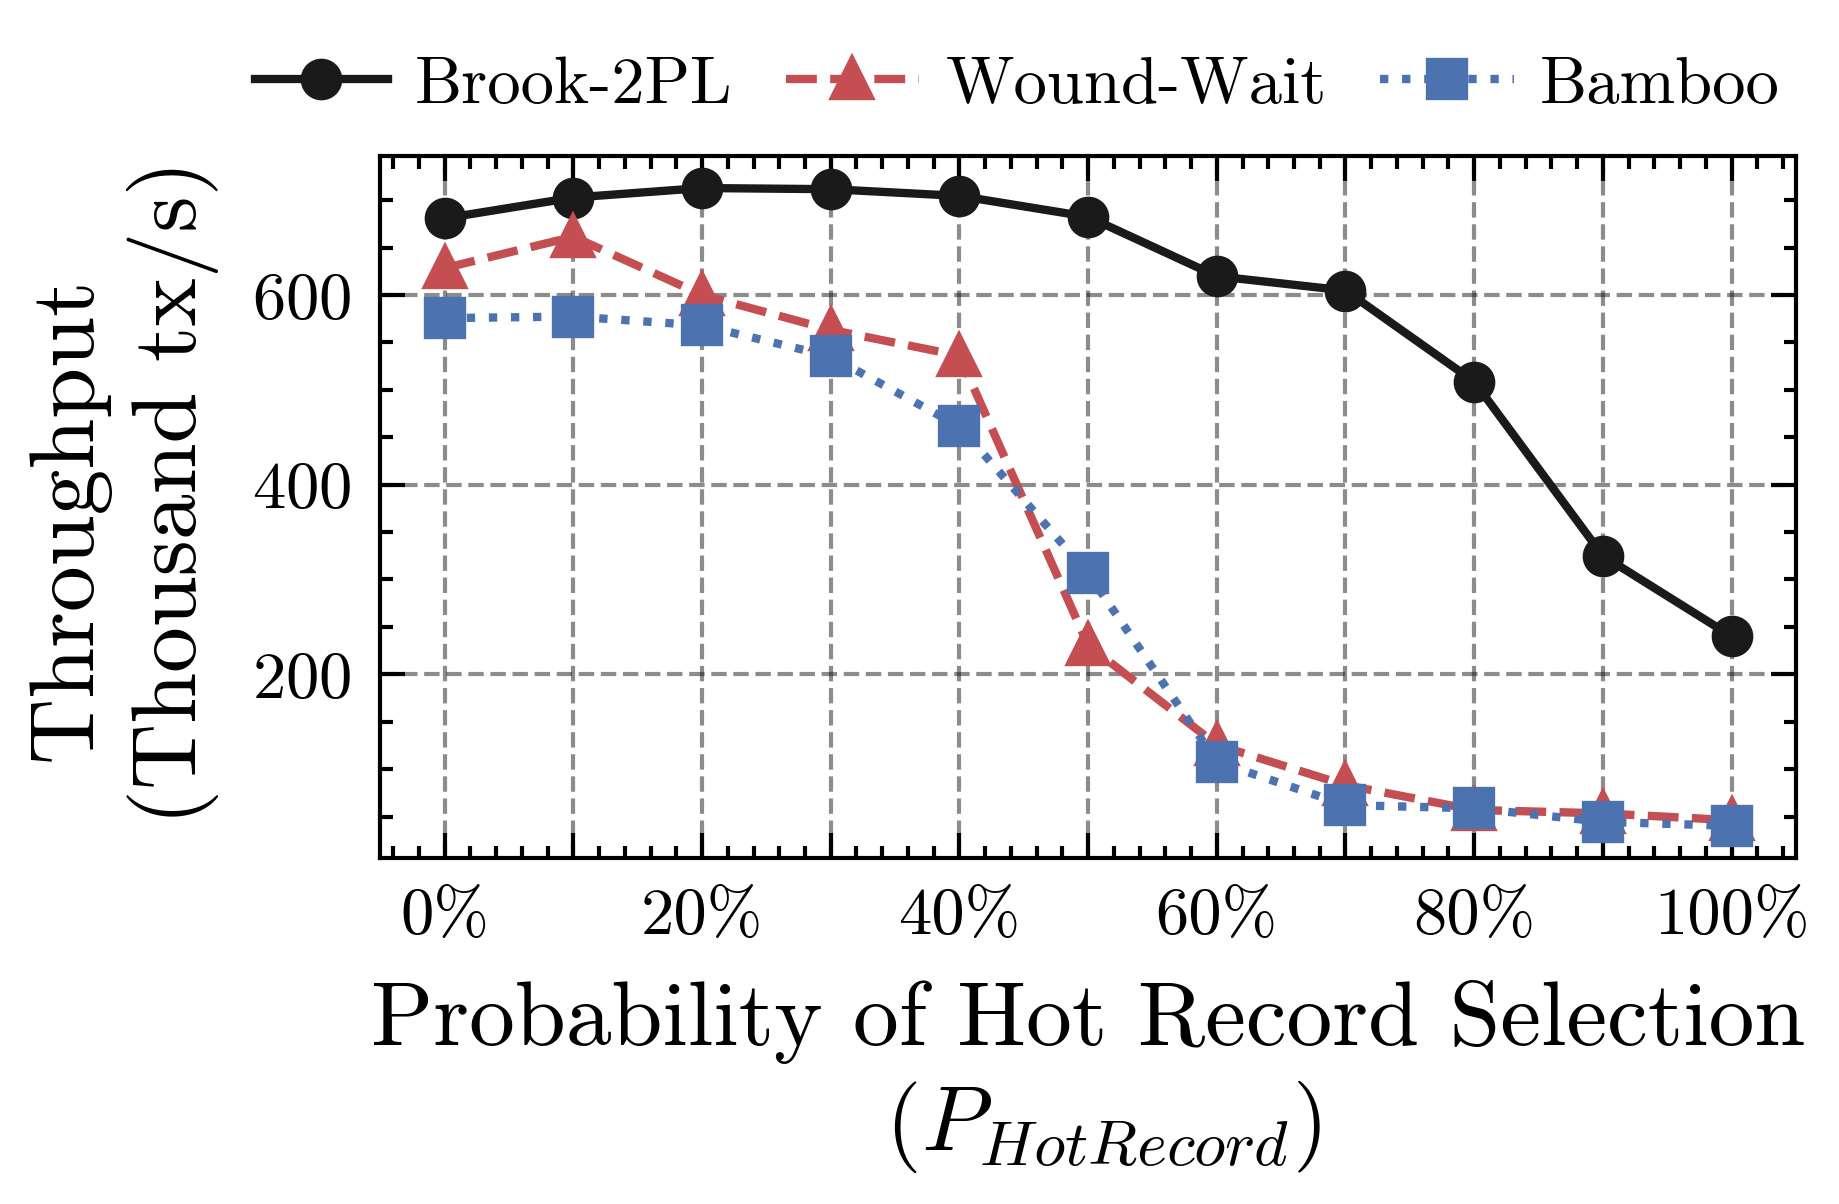

In [52]:
df = pd.read_csv('store-results.csv')


# Get Matplotlib's default color cycle
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Map each hotness level to a specific color from the color cycle

markers = {
    'slw': 'o',        # Circle for SLW-Graph
    'bamboo': 's',     # Square for Bamboo
    'ww': '^'          # Triangle for Wound-Wait
}

# Determine the number of unique delays
unique_delays = sorted(pd.unique(df['operation_delay']))
num_delays = len(unique_delays)

# # Create subplots
# fig, axes = plt.subplots(nrows=num_delays, ncols=1, figsize=(10, 5 * num_delays), sharex=True)

# # If only one delay, ensure axes is iterable
# if num_delays == 1:
#     axes = [axes]



plt.figure(figsize=(3.2, 2.2))

filtered_df = df[(df['operation_delay'] == 0)]
filtered_df = filtered_df[filtered_df['hot_records'] == '../rocksdb/hotspots/hot_records_64_items']


# Plot each mode separately
for mode in ['slw', 'ww', 'bamboo']:
    mode_data = filtered_df[filtered_df['mode'] == mode]
    plt.plot(
        mode_data['prob'],
        mode_data['throughput(tx/s)']/1000,
        label=mode,  # Add the mode to the legend
        # marker = True,
        marker=markers[mode],
        # linestyle='-',  # Solid line
        # linewidth=1.5,
        markersize=4
    )


# plt.title('Performance for Store-Generated Workload')
plt.xlabel('Probability of Hot Record Selection\n ($P_{HotRecord}$)', fontsize=11)
plt.ylabel('Throughput \n (Thousand tx/s)', fontsize=11)

# Custom legend labels
custom_labels = {'slw': 'Brook-2PL', 'bamboo': 'Bamboo', 'ww': 'Wound-Wait'}
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [custom_labels[label] for label in labels if label in custom_labels]

# Custom legend labels
custom_labels = {'slw': 'Brook-2PL', 'bamboo': 'Bamboo', 'ww': 'Wound-Wait'}
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [custom_labels[label] for label in labels if label in custom_labels]
# plt.legend(handles, new_labels)

# # ax.legend(handles, labels,  bbox_to_anchor=(1, 1), loc='upper left')
plt.legend(
    handles, new_labels,
    bbox_to_anchor=(0.45, 1.1),  # Position above the plot
    loc='center',                # Center-align
    ncol=len(handles),           # Single-line legend
    frameon=False ,               # Optional: Remove legend border
      handletextpad=0.4,           # Reduce space between handles and text
    columnspacing=0.8,          # Reduce space between legend columns,
    fontsize=8
)

# ticks with percent
prob = range(0, 110, 10)
prob_str = [str(prob[i]) + "%" if prob[i] % 20 == 0 else "" for i in range(0, len(prob))]
plt.xticks(prob, labels=prob_str)

plt.grid(True)



plt.tight_layout()
plt.plot()
plt.savefig('performance_store_varyingProb_64.pdf', bbox_inches='tight')

In [53]:
speedupWW = np.array(filtered_df[filtered_df['mode'] == 'slw']['throughput(tx/s)']) / np.array(filtered_df[filtered_df['mode'] == 'ww']['throughput(tx/s)'])
speedupBamboo = np.array(filtered_df[filtered_df['mode'] == 'slw']['throughput(tx/s)']) / np.array(filtered_df[filtered_df['mode'] == 'bamboo']['throughput(tx/s)'])
avg = (speedupWW + speedupBamboo) / 2
avg.mean()

np.float64(3.978364747264733)

In [54]:
avg

array([1.133195  , 1.13994547, 1.22148526, 1.29647484, 1.42058508,
       2.59297871, 5.34392453, 8.51041262, 8.80206078, 6.70580479,
       5.59514513])

10    NaN
32    NaN
43    NaN
65    NaN
76    NaN
98    NaN
109   NaN
131   NaN
Name: throughput(tx/s), dtype: float64


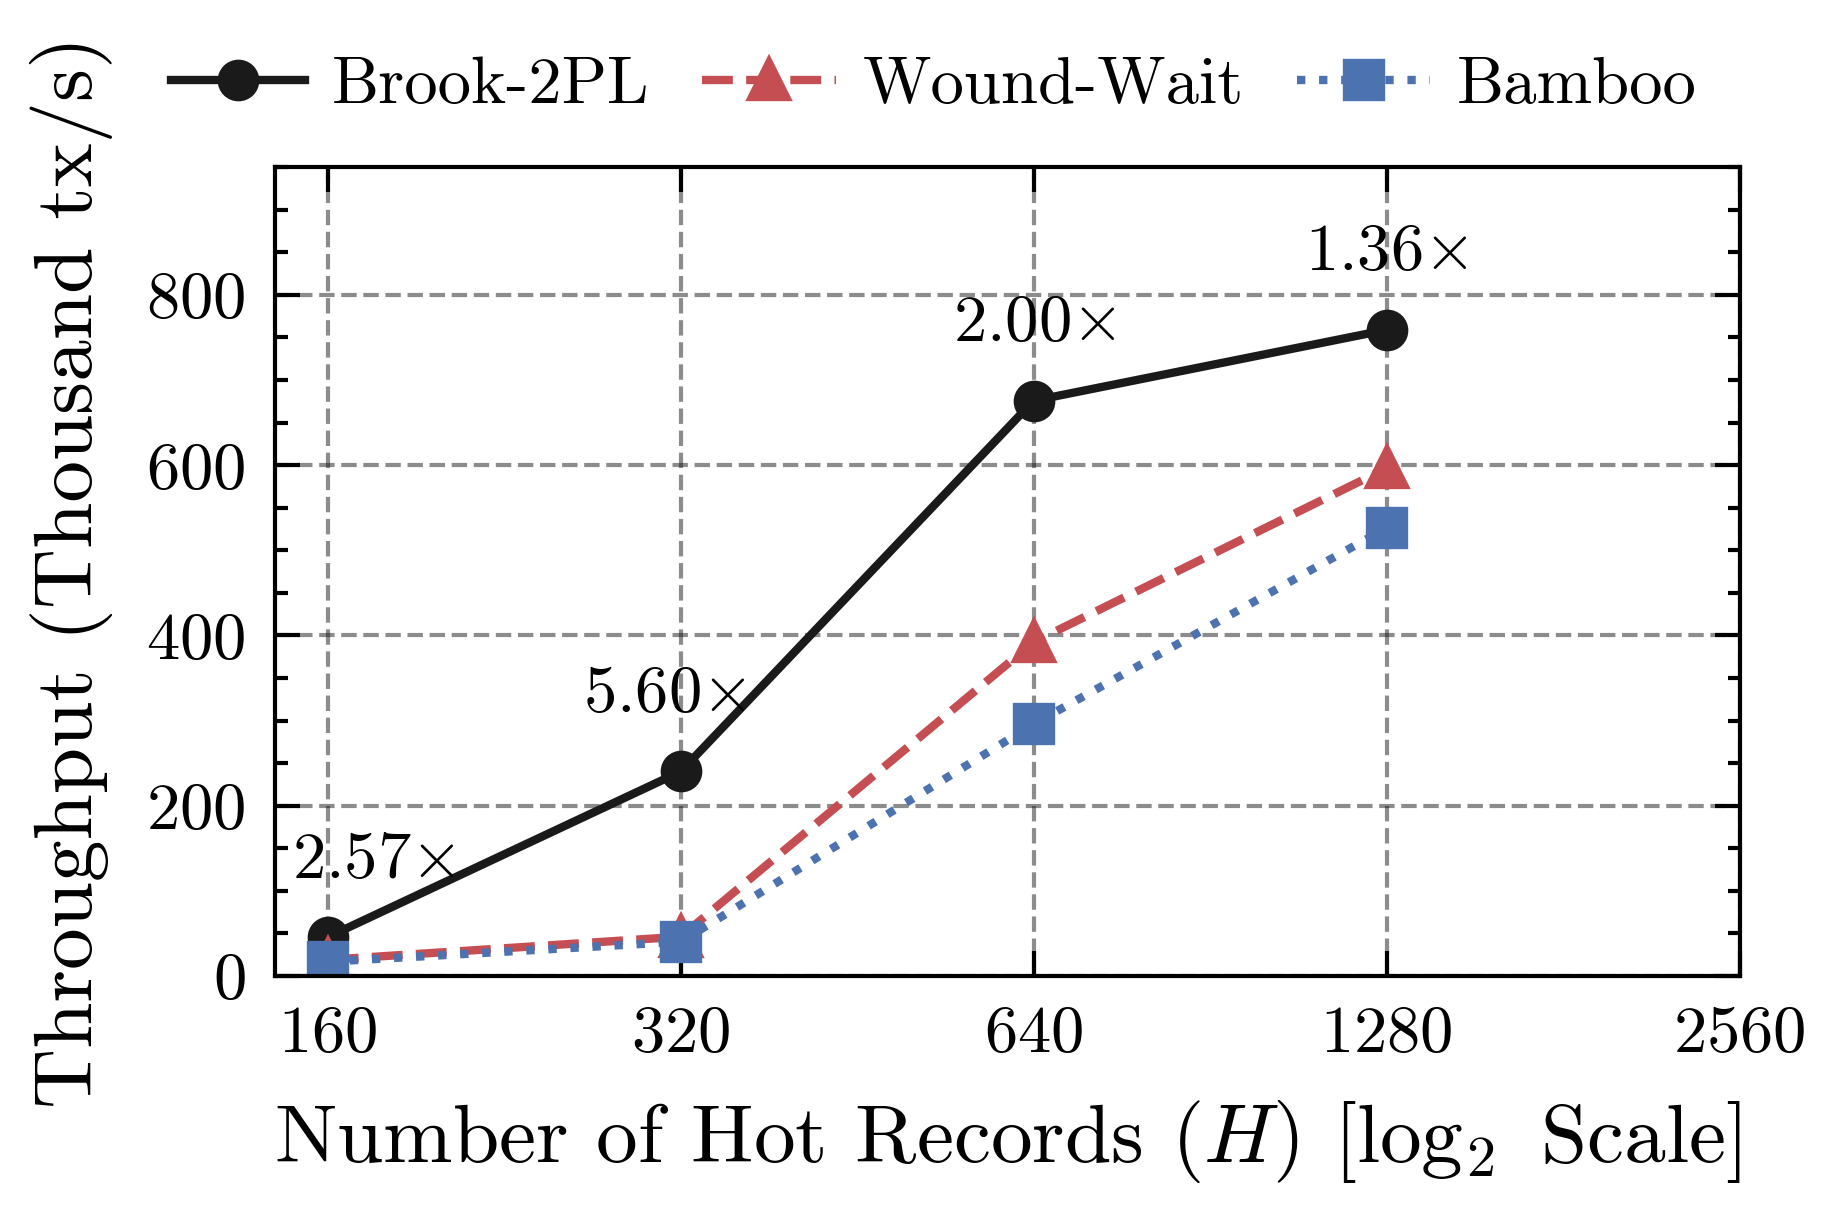

In [55]:
df = pd.read_csv('store-results.csv')

df['hotness'] = df['hot_records'].apply(lambda x: 8 if x == '../rocksdb/hotspots/hot_records_8_items' \
                                        else 16 if x == '../rocksdb/hotspots/hot_records_16_items' \
                                        else 32 if x == '../rocksdb/hotspots/hot_records_32_items' \
                                        else 64 if x == '../rocksdb/hotspots/hot_records_64_items' \
                                        else 128 if x == '../rocksdb/hotspots/hot_records_128_items' \
                                        else 256 if x == '../rocksdb/hotspots/hot_records_256_items' \
                                        else 512)
df['hotness'] = df['hotness'].apply(lambda x: x * 5)

# Get Matplotlib's default color cycle and map each hotness level to a specific color
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
hotness_color_map = {hotness: color for hotness, color in zip(pd.unique(df['hot_records']), colors)}

markers = {
    'slw': 'o',        # Circle for SLW-Graph
    'bamboo': 's',     # Square for Bamboo
    'ww': '^'          # Triangle for Wound-Wait
}

# plt.figure(figsize=(4.32, 1.8))
plt.figure(figsize=(3.2, 2.2))

filtered_df = df[(df['operation_delay'] == 0)]
filtered_df = filtered_df[filtered_df['prob'] == 100]

# Print the ratio of SLW throughput to Bamboo throughput for reference
print(filtered_df[filtered_df['mode'] == 'slw']['throughput(tx/s)'] /
      filtered_df[filtered_df['mode'] == 'bamboo']['throughput(tx/s)'])

# Plot each mode separately
for mode in ['slw', 'ww', 'bamboo']:
    mode_data = filtered_df[filtered_df['mode'] == mode]
    mode_data = mode_data.sort_values(by='hotness')
    plt.plot(
        mode_data['hotness'],
        mode_data['throughput(tx/s)'] / 1000,
        label=mode,
        marker=markers[mode],
        markersize=4
    )
    # Add annotation for the SLW mode similar to the other graph
    if mode == 'slw':
        # Compute speedup relative to WW and Bamboo modes
        speedupWW = np.array(mode_data['throughput(tx/s)']) / np.array(filtered_df[filtered_df['mode'] == 'ww']['throughput(tx/s)'])
        speedupBamboo = np.array(mode_data['throughput(tx/s)']) / np.array(filtered_df[filtered_df['mode'] == 'bamboo']['throughput(tx/s)'])
        avg = (speedupWW + speedupBamboo) / 2
        for i in range(len(mode_data['throughput(tx/s)'])):
          j = 0
          if i == 0:
            j = 15
          elif i == 1:
            j = -10
          elif i== 4:
            j = -50
          plt.annotate(
              f'${avg[i]:.2f}$' + r'$ \times $',
              (np.array(mode_data['hotness'])[i] + j,
                np.array(mode_data['throughput(tx/s)'])[i] / 1000 + 70),
              ha='center',
              fontweight='bold'
          )

plt.xlabel('Number of Hot Records ($H$) [$\log_2$ Scale]', fontsize=10)
plt.ylabel('Throughput (Thousand tx/s)', fontsize=10)
plt.xscale("log", base=2)



# Custom legend labels
custom_labels = {'slw': 'Brook-2PL', 'bamboo': 'Bamboo', 'ww': 'Wound-Wait'}
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [custom_labels[label] for label in labels if label in custom_labels]
# plt.legend(handles, new_labels)
plt.legend(
    handles, new_labels,
    bbox_to_anchor=(0.45, 1.1),  # Position above the plot
    loc='center',                # Center-align
    ncol=len(handles),           # Single-line legend
    frameon=False ,               # Optional: Remove legend border
      handletextpad=0.4,           # Reduce space between handles and text
    columnspacing=0.8,          # Reduce space between legend columns,
    fontsize=8
)

plt.grid(True)
plt.gca().xaxis.set_major_formatter(plt.ScalarFormatter())


plt.ylim(0, 950)
plt.xticks([32 * 5, 64 * 5, 128 * 5, 256 * 5, 512 * 5])

plt.tight_layout()
plt.savefig('performance_store_varyingItems_100.pdf', bbox_inches='tight')


# Latency Store

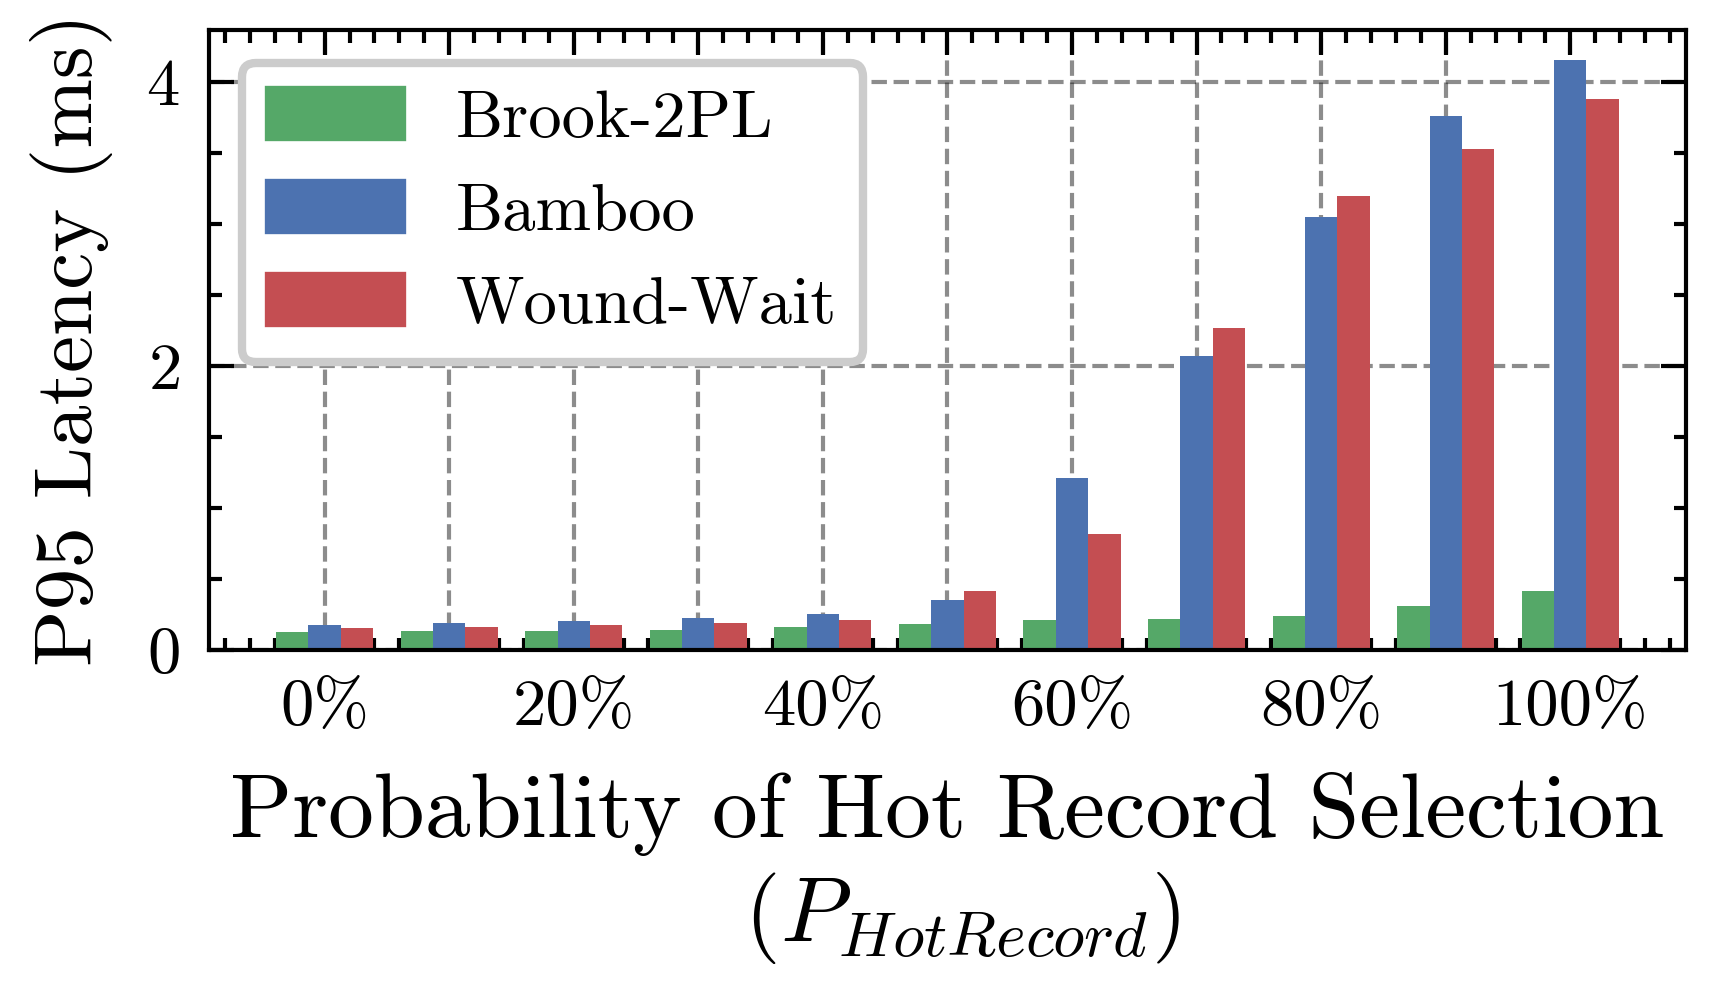

In [56]:
df = pd.read_csv('store-results.csv')
# def b_plot(col='throughput(tx/s)', col_name='Throughput (tx/s)'):
col='95th_latency'
# Get Matplotlib's default color cycle
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Assign colors from the default color cycle to the methods
method_colors = {
    'slw': colors[3],        # First color for SLW-Graph
    'ww': colors[1],     # Second color for Bamboo
    'bamboo': colors[2]          # Third color for Wound-Wait
}

# Determine the number of unique delays and hotness levels
unique_delays = sorted(pd.unique(df['operation_delay']))
unique_hotness = pd.unique(df['hot_records'])
num_delays = 1
num_hotness = 1

plt.figure(figsize=(3, 1.8))
# Width of the bars
bar_width = 0.26


# Custom legend for methods
method_legend = [
    mpatches.Patch(color=method_colors['slw'], label='Brook-2PL'),
    mpatches.Patch(color=method_colors['bamboo'], label='Bamboo'),
    mpatches.Patch(color=method_colors['ww'], label='Wound-Wait')
]

# Iterate over each operation delay
i = 0
j = 0
delay = 0
hotness = '../rocksdb/hotspots/hot_records_64_items'
#   # Iterate over each operation delay
# for i, delay in enumerate(unique_delays):
#     # Iterate over each hotness level
#     for j, hotness in enumerate(unique_hotness):
#       # Iterate over each hotness level
# for j, hotness in enumerate(unique_hotness):
# ax = axes[i][j]
filtered_df = df[(df['operation_delay'] == delay) & (df['hot_records'] == hotness)]
prob = range(0, 110, 10)
# Positioning bars
indices = np.arange(len(prob))
slw_latency = filtered_df[filtered_df['mode'] == 'slw'][col]
# Bar plots for each mode with specific colors
plt.bar(indices, np.array(filtered_df[filtered_df['mode'] == 'slw'][col])/1000, width=bar_width, label='SLW-Graph', color=method_colors['slw'])
plt.bar(indices + 2 * bar_width,  np.array(filtered_df[filtered_df['mode'] == 'ww'][col])/1000, width=bar_width, label='Wound-Wait', color=method_colors['ww'])
plt.bar(indices + bar_width, np.array(filtered_df[filtered_df['mode'] == 'bamboo'][col])/1000, width=bar_width, label='Bamboo', color=method_colors['bamboo'])



# plt.title('Latency for Store-Generated Workload')
plt.xlabel('Probability of Hot Record Selection\n ($P_{HotRecord}$)', fontsize=11)
plt.ylabel('P95 Latency (ms)', fontsize=10)
plt.grid(True)

# Adjusting x-ticks to show properly in the center of grouped bars
prob = range(0, 110, 10)
prob_str = [str(prob[i]) + "%" if prob[i] % 20 == 0 else "" for i in range(0, len(prob))]

plt.xticks(indices + bar_width, labels=prob_str)

# plt.xticklabels(prob)

# Ensure all axes show numbers
# ax.tick_params(axis='both', which='both', labelsize=10)
plt.legend(handles=method_legend)


  # Add a global legend outside the subplots
  # fig.legend(handles=method_legend, loc='upper center', ncol=num_hotness, bbox_to_anchor=(0.5, 1.05))

plt.tight_layout()
plt.plot()
plt.savefig('latency_store_varingProb_64.pdf', bbox_inches='tight')
plt.show()

In [57]:
slw_latency, ww_latency, bamboo_latency = filtered_df[filtered_df['mode'] == 'slw']['95th_latency'], filtered_df[filtered_df['mode'] == 'ww']['95th_latency'], filtered_df[filtered_df['mode'] == 'bamboo']['95th_latency']

In [58]:
((np.array(bamboo_latency) - np.array(slw_latency)) / np.array(bamboo_latency) * 100).mean()

np.float64(60.128969582728026)

In [59]:
((np.array(ww_latency) - np.array(slw_latency)) / np.array(ww_latency) * 100).mean()

np.float64(54.57235094554078)

#Threads (Store + TPCC)


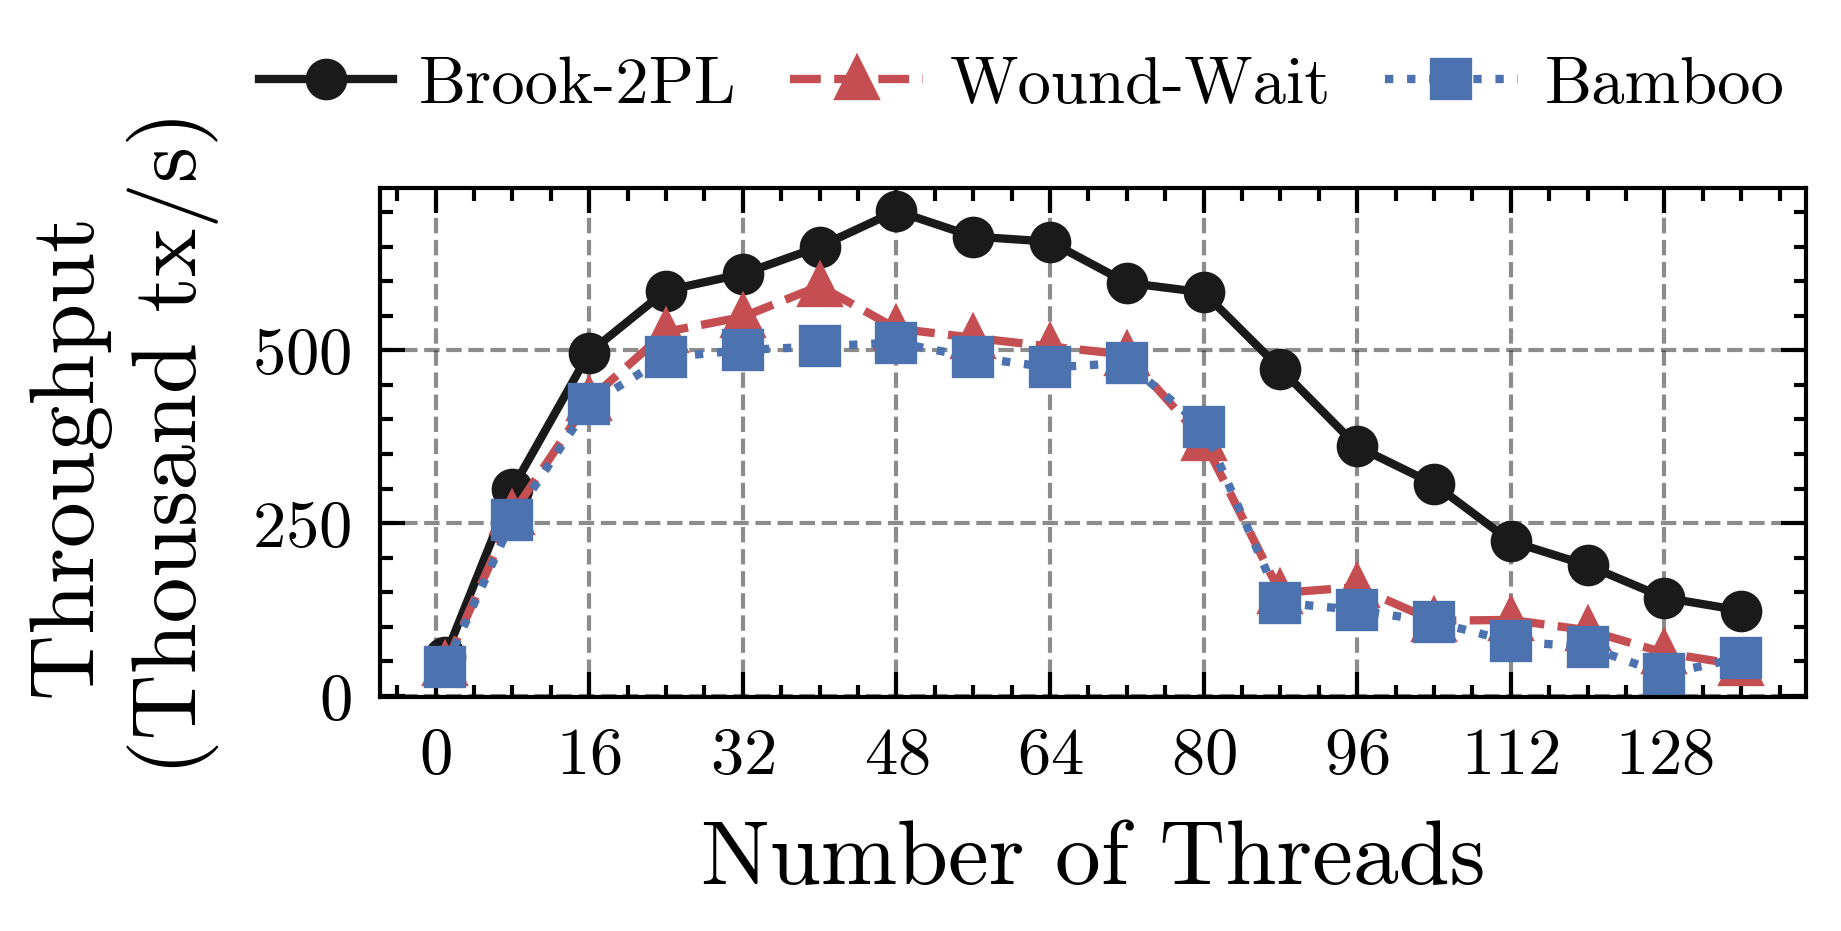

In [60]:
df = pd.read_csv('store-threads.csv')


# Get Matplotlib's default color cycle
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Map each hotness level to a specific color from the color cycle

markers = {
    'slw': 'o',        # Circle for SLW-Graph
    'bamboo': 's',     # Square for Bamboo
    'ww': '^'          # Triangle for Wound-Wait
}

# Determine the number of unique delays
unique_delays = sorted(pd.unique(df['operation_delay']))
num_delays = len(unique_delays)

# # Create subplots
# fig, axes = plt.subplots(nrows=num_delays, ncols=1, figsize=(10, 5 * num_delays), sharex=True)

# # If only one delay, ensure axes is iterable
# if num_delays == 1:
#     axes = [axes]



plt.figure(figsize=(3.2, 1.8))

filtered_df = df[(df['operation_delay'] == 0)]
filtered_df = filtered_df[filtered_df['hot_records'] == '../rocksdb/hotspots/hot_records_64_items']
filtered_df = filtered_df[filtered_df['prob'] == 30]


# Plot each mode separately
for mode in ['slw', 'ww', 'bamboo']:
    mode_data = filtered_df[filtered_df['mode'] == mode]
    plt.plot(
        mode_data['threads'],
        mode_data['throughput(tx/s)']/1000,
        label=mode,  # Add the mode to the legend
        # marker = True,
        marker=markers[mode],
        # linestyle='-',  # Solid line
        # linewidth=1.5,
        markersize=4
    )


# plt.title('Performance for Store-Generated Workload')
plt.xlabel('Number of Threads', fontsize=11)
plt.ylabel('Throughput \n(Thousand tx/s)', fontsize=11)

# Custom legend labels
custom_labels = {'slw': 'Brook-2PL', 'bamboo': 'Bamboo', 'ww': 'Wound-Wait'}
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [custom_labels[label] for label in labels if label in custom_labels]
# plt.legend(handles, new_labels)

# ax.legend(handles, labels,  bbox_to_anchor=(1, 1), loc='upper left')
plt.legend(
    handles, new_labels,
    bbox_to_anchor=(0.45, 1.2),  # Position above the plot
    loc='center',                # Center-align
    ncol=len(handles),           # Single-line legend
    frameon=False ,               # Optional: Remove legend border
      handletextpad=0.4,           # Reduce space between handles and text
    columnspacing=0.8,          # Reduce space between legend columns,
    fontsize=8
)


# ticks with percent
# prob = range(0, 110, 10)
# prob_str = [str(prob[i]) + "%" if prob[i] % 20 == 0 else "" for i in range(0, len(prob))]
# plt.xticks(prob, labels=prob_str)
plt.xticks(range(0, 137, 16))
plt.grid(True)





plt.tight_layout()
plt.plot()
plt.savefig('performance_store_varyingThreads_30p.pdf', bbox_inches='tight')

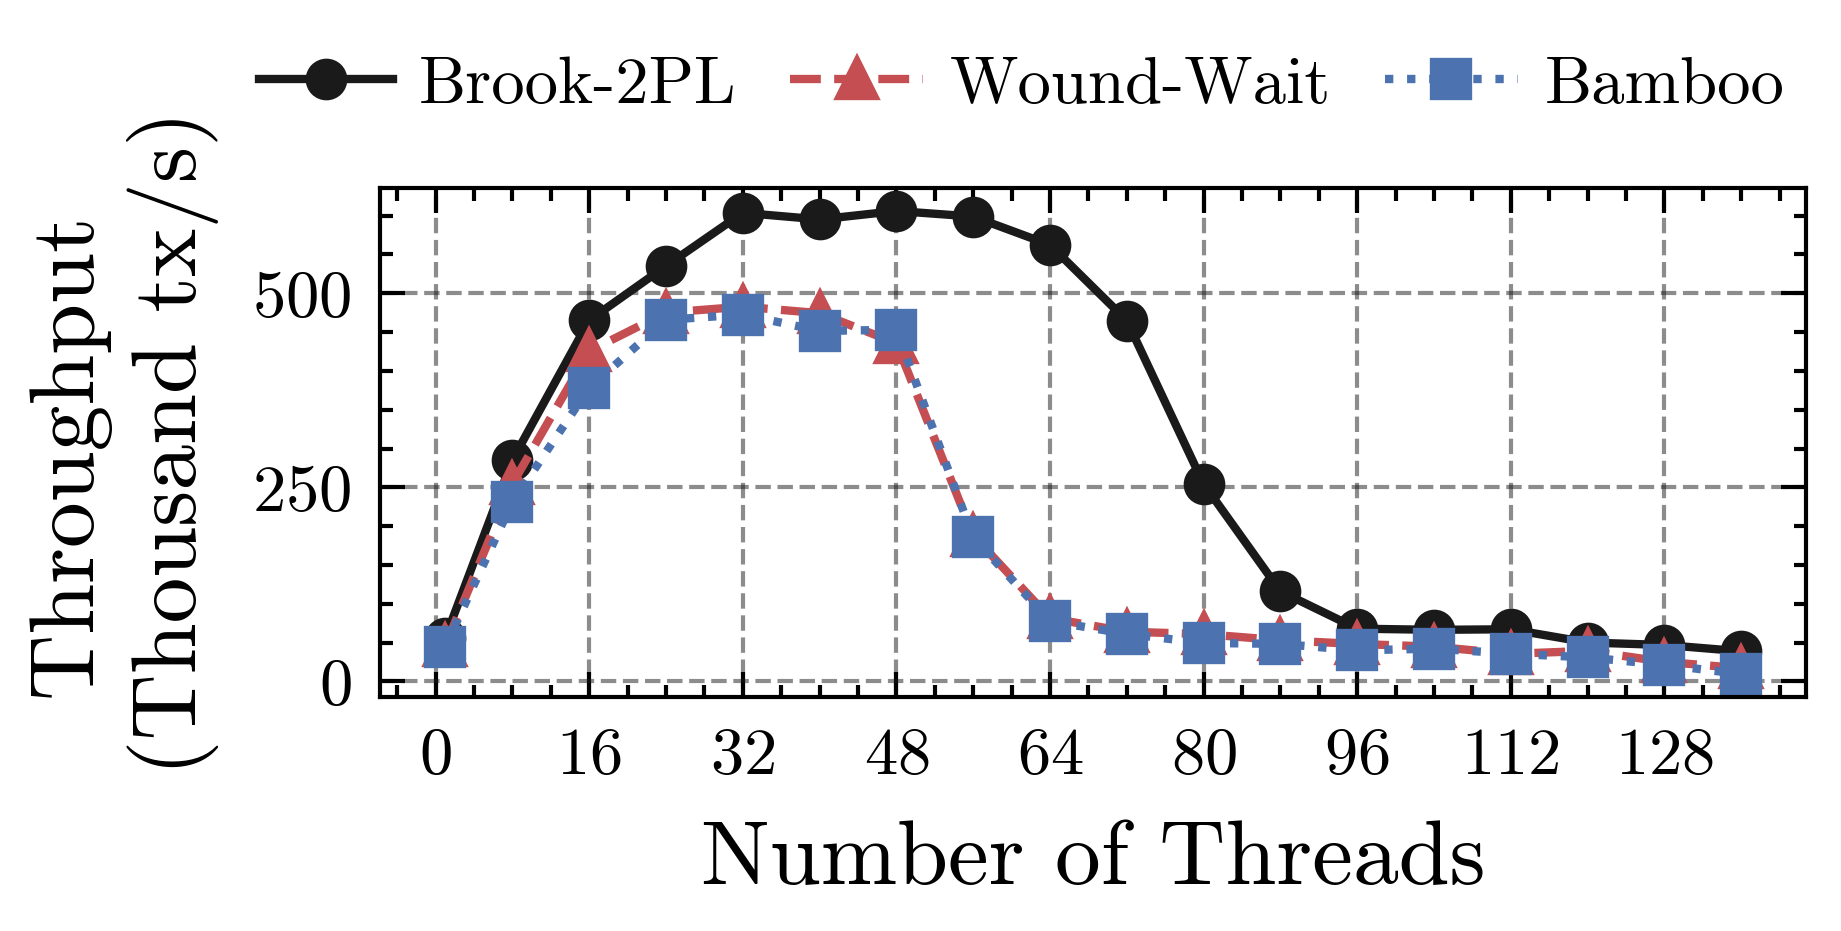

In [61]:
df = pd.read_csv('store-threads.csv')


# Get Matplotlib's default color cycle
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Map each hotness level to a specific color from the color cycle

markers = {
    'slw': 'o',        # Circle for SLW-Graph
    'bamboo': 's',     # Square for Bamboo
    'ww': '^'          # Triangle for Wound-Wait
}

# Determine the number of unique delays
unique_delays = sorted(pd.unique(df['operation_delay']))
num_delays = len(unique_delays)

# # Create subplots
# fig, axes = plt.subplots(nrows=num_delays, ncols=1, figsize=(10, 5 * num_delays), sharex=True)

# # If only one delay, ensure axes is iterable
# if num_delays == 1:
#     axes = [axes]



plt.figure(figsize=(3.2, 1.8))

filtered_df = df[(df['operation_delay'] == 0)]
filtered_df = filtered_df[filtered_df['hot_records'] == '../rocksdb/hotspots/hot_records_64_items']
filtered_df = filtered_df[filtered_df['prob'] == 70]


# Plot each mode separately
for mode in ['slw', 'ww', 'bamboo']:
    mode_data = filtered_df[filtered_df['mode'] == mode]
    plt.plot(
        mode_data['threads'],
        mode_data['throughput(tx/s)']/1000,
        label=mode,  # Add the mode to the legend
        # marker = True,
        marker=markers[mode],
        # linestyle='-',  # Solid line
        # linewidth=1.5,
        markersize=4
    )


# plt.title('Performance for Store-Generated Workload')
plt.xlabel('Number of Threads', fontsize=11)
plt.ylabel('Throughput \n(Thousand tx/s)', fontsize=11)

# Custom legend labels
custom_labels = {'slw': 'Brook-2PL', 'bamboo': 'Bamboo', 'ww': 'Wound-Wait'}
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [custom_labels[label] for label in labels if label in custom_labels]
# plt.legend(handles, new_labels)

# ax.legend(handles, labels,  bbox_to_anchor=(1, 1), loc='upper left')
plt.legend(
    handles, new_labels,
    bbox_to_anchor=(0.45, 1.2),  # Position above the plot
    loc='center',                # Center-align
    ncol=len(handles),           # Single-line legend
    frameon=False ,               # Optional: Remove legend border
      handletextpad=0.4,           # Reduce space between handles and text
    columnspacing=0.8,          # Reduce space between legend columns,
    fontsize=8
)


# ticks with percent
# prob = range(0, 110, 10)
# prob_str = [str(prob[i]) + "%" if prob[i] % 20 == 0 else "" for i in range(0, len(prob))]
# plt.xticks(prob, labels=prob_str)
plt.xticks(range(0, 137, 16))
plt.grid(True)





plt.tight_layout()
plt.plot()
plt.savefig('performance_store_varyingThreads_70p.pdf', bbox_inches='tight')

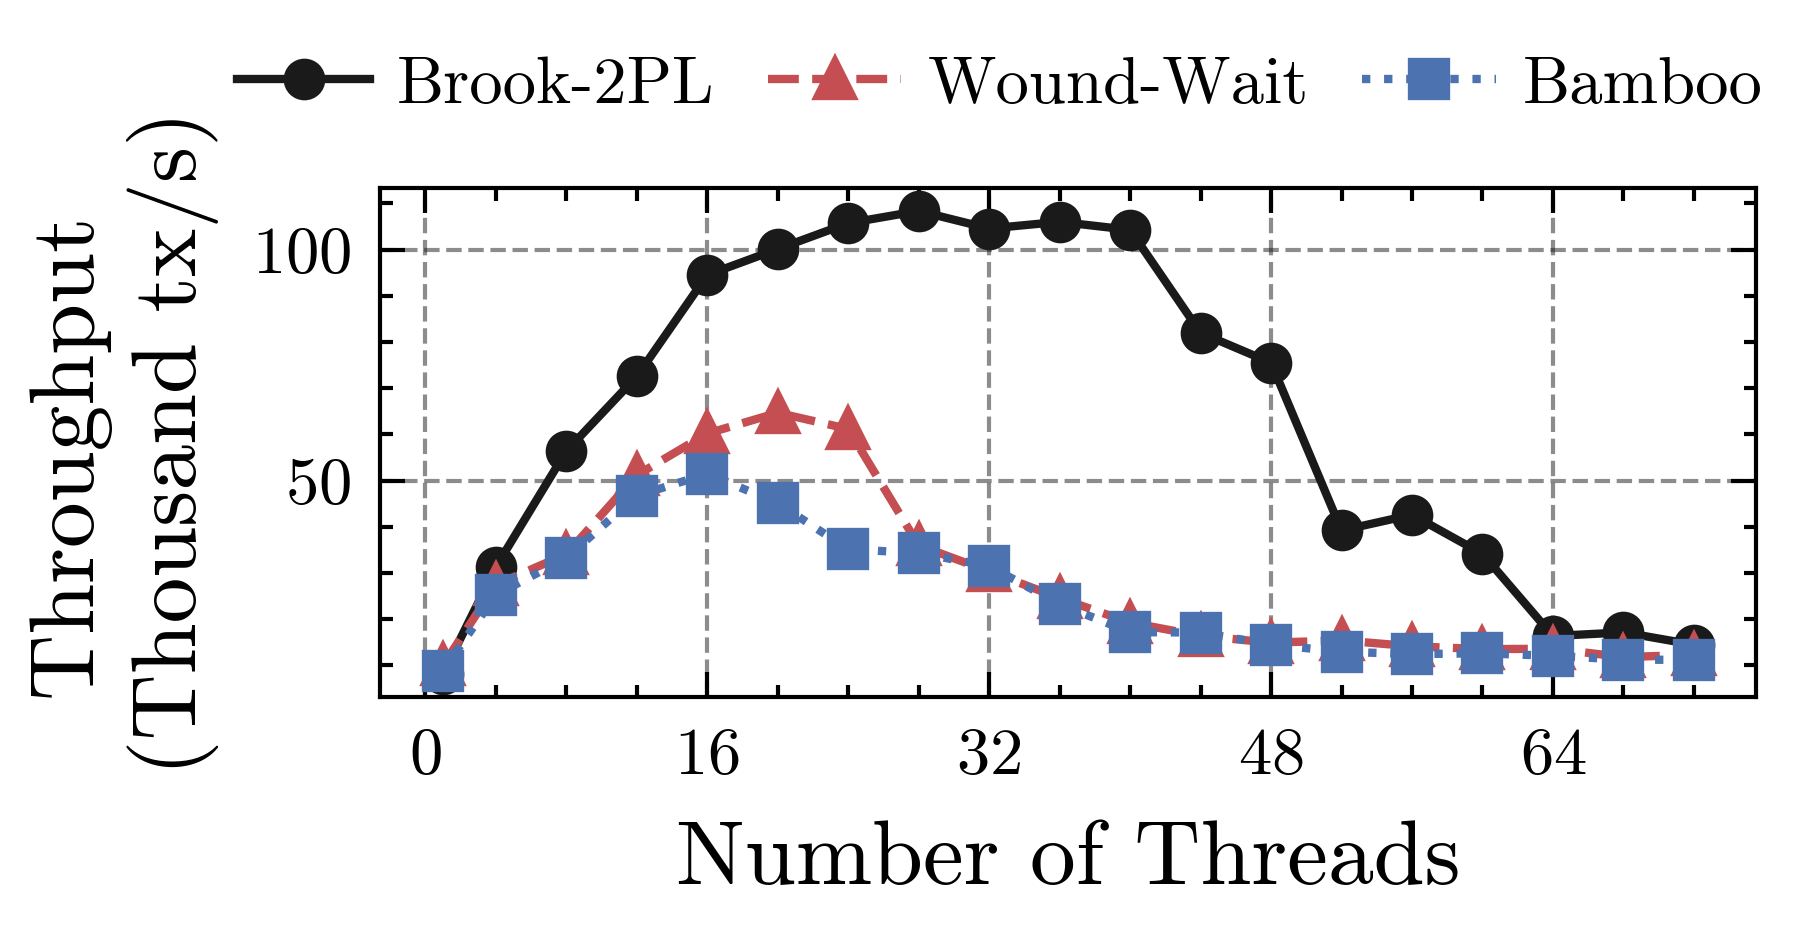

In [62]:
df = pd.read_csv('tpcc-threads.csv')


# Get Matplotlib's default color cycle
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Map each hotness level to a specific color from the color cycle

markers = {
    'slw': 'o',        # Circle for SLW-Graph
    'bamboo': 's',     # Square for Bamboo
    'ww': '^'          # Triangle for Wound-Wait
}

# Determine the number of unique delays
unique_delays = sorted(pd.unique(df['operation_delay']))
num_delays = len(unique_delays)

# # Create subplots
# fig, axes = plt.subplots(nrows=num_delays, ncols=1, figsize=(10, 5 * num_delays), sharex=True)

# # If only one delay, ensure axes is iterable
# if num_delays == 1:
#     axes = [axes]



plt.figure(figsize=(3.2, 1.8))

filtered_df = df[(df['operation_delay'] == 0)]
filtered_df = filtered_df[filtered_df['threads'] <= 72]


# Plot each mode separately
for mode in ['slw', 'ww', 'bamboo']:
    mode_data = filtered_df[filtered_df['mode'] == mode]
    plt.plot(
        mode_data['threads'],
        mode_data['throughput(tx/s)']/1000,
        label=mode,  # Add the mode to the legend
        # marker = True,
        marker=markers[mode],
        # linestyle='-',  # Solid line
        # linewidth=1.5,
        markersize=4
    )


# plt.title('Performance for Store-Generated Workload')
plt.xlabel('Number of Threads', fontsize=11)
plt.ylabel('Throughput \n(Thousand tx/s)', fontsize=11)

# Custom legend labels
custom_labels = {'slw': 'Brook-2PL', 'bamboo': 'Bamboo', 'ww': 'Wound-Wait'}
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [custom_labels[label] for label in labels if label in custom_labels]
# plt.legend(handles, new_labels)

# ax.legend(handles, labels,  bbox_to_anchor=(1, 1), loc='upper left')
plt.legend(
    handles, new_labels,
    bbox_to_anchor=(0.45, 1.2),  # Position above the plot
    loc='center',                # Center-align
    ncol=len(handles),           # Single-line legend
    frameon=False ,               # Optional: Remove legend border
      handletextpad=0.4,           # Reduce space between handles and text
    columnspacing=0.8,          # Reduce space between legend columns,
    fontsize=8
)


# ticks with percent
# prob = range(0, 110, 10)
# prob_str = [str(prob[i]) + "%" if prob[i] % 20 == 0 else "" for i in range(0, len(prob))]
# plt.xticks(prob, labels=prob_str)
plt.xticks(range(0, 137, 16))
plt.grid(True)





plt.tight_layout()
plt.plot()
plt.savefig('performance_tpcc_varyingThreads_100p.pdf', bbox_inches='tight')

# Items

In [63]:
def item_performance(itemNum = 20, H = 32):
  df = pd.read_csv('store-items.csv')


  # Get Matplotlib's default color cycle
  colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

  # Map each hotness level to a specific color from the color cycle

  markers = {
      'slw': 'o',        # Circle for SLW-Graph
      'bamboo': 's',     # Square for Bamboo
      'ww': '^'          # Triangle for Wound-Wait
  }

  # Determine the number of unique delays
  # unique_delays = sorted(pd.unique(df['operation_delay']))
  # num_delays = len(unique_delays)

  # # Create subplots
  # fig, axes = plt.subplots(nrows=num_delays, ncols=1, figsize=(10, 5 * num_delays), sharex=True)

  # # If only one delay, ensure axes is iterable
  # if num_delays == 1:
  #     axes = [axes]



  plt.figure(figsize=(4.32, 1.6))

  filtered_df = df[(df['operation_delay'] == 0)]
  filtered_df = filtered_df[filtered_df['hot_records'] == f'../rocksdb/hotspots/hot_records_{H}_items']
  # filtered_df = filtered_df[filtered_df['item read'] == itemNum]

  # filtered_df = filtered_df[filtered_df['hot_records'] == '../rocksdb/hotspots/hot_records_32_items']

  # Plot each mode separately
  for mode in ['slw', 'ww', 'bamboo']:
      mode_data = filtered_df[filtered_df['mode'] == mode]
      plt.plot(
          mode_data['prob'],
          mode_data['item_read(tx/s)']/1000,
          label=mode,  # Add the mode to the legend
          # marker = True,
          marker=markers[mode],
          # linestyle='-',  # Solid line
          # linewidth=1.5,
          markersize=4
      )


  # plt.title(f'Number of Hot Records ($H$) $= {H * 5}$')
  plt.xlabel('Probability of Hot Record Selection ($P_{HotRecord}$)', fontsize=11)
  plt.ylabel('Throughput\n (Thousand tx/s)', fontsize=11)

  # Custom legend labels
  custom_labels = {'slw': 'Brook-2PL', 'bamboo': 'Bamboo', 'ww': 'Wound-Wait'}
  handles, labels = plt.gca().get_legend_handles_labels()
  new_labels = [custom_labels[label] for label in labels if label in custom_labels]
  # plt.legend(handles, new_labels)


  # ax.legend(handles, labels,  bbox_to_anchor=(1, 1), loc='upper left')
  plt.legend(
      handles, new_labels,
      bbox_to_anchor=(0.45, 1.1),  # Position above the plot
      loc='center',                # Center-align
      ncol=len(handles),           # Single-line legend
      frameon=False ,               # Optional: Remove legend border
        handletextpad=0.4,           # Reduce space between handles and text
      columnspacing=0.8,          # Reduce space between legend columns,
      fontsize=8
  )

  # ticks with percent
  prob = range(0, 110, 10)
  prob_str = [str(prob[i]) + "%" if prob[i] % 20 == 0 else "" for i in range(0, len(prob))]
  plt.xticks(prob, labels=prob_str)

  plt.grid(True)



  plt.tight_layout()
  plt.plot()
  plt.savefig(f'readonly_varyingProb_{H}_{itemNum}items.pdf', bbox_inches='tight')

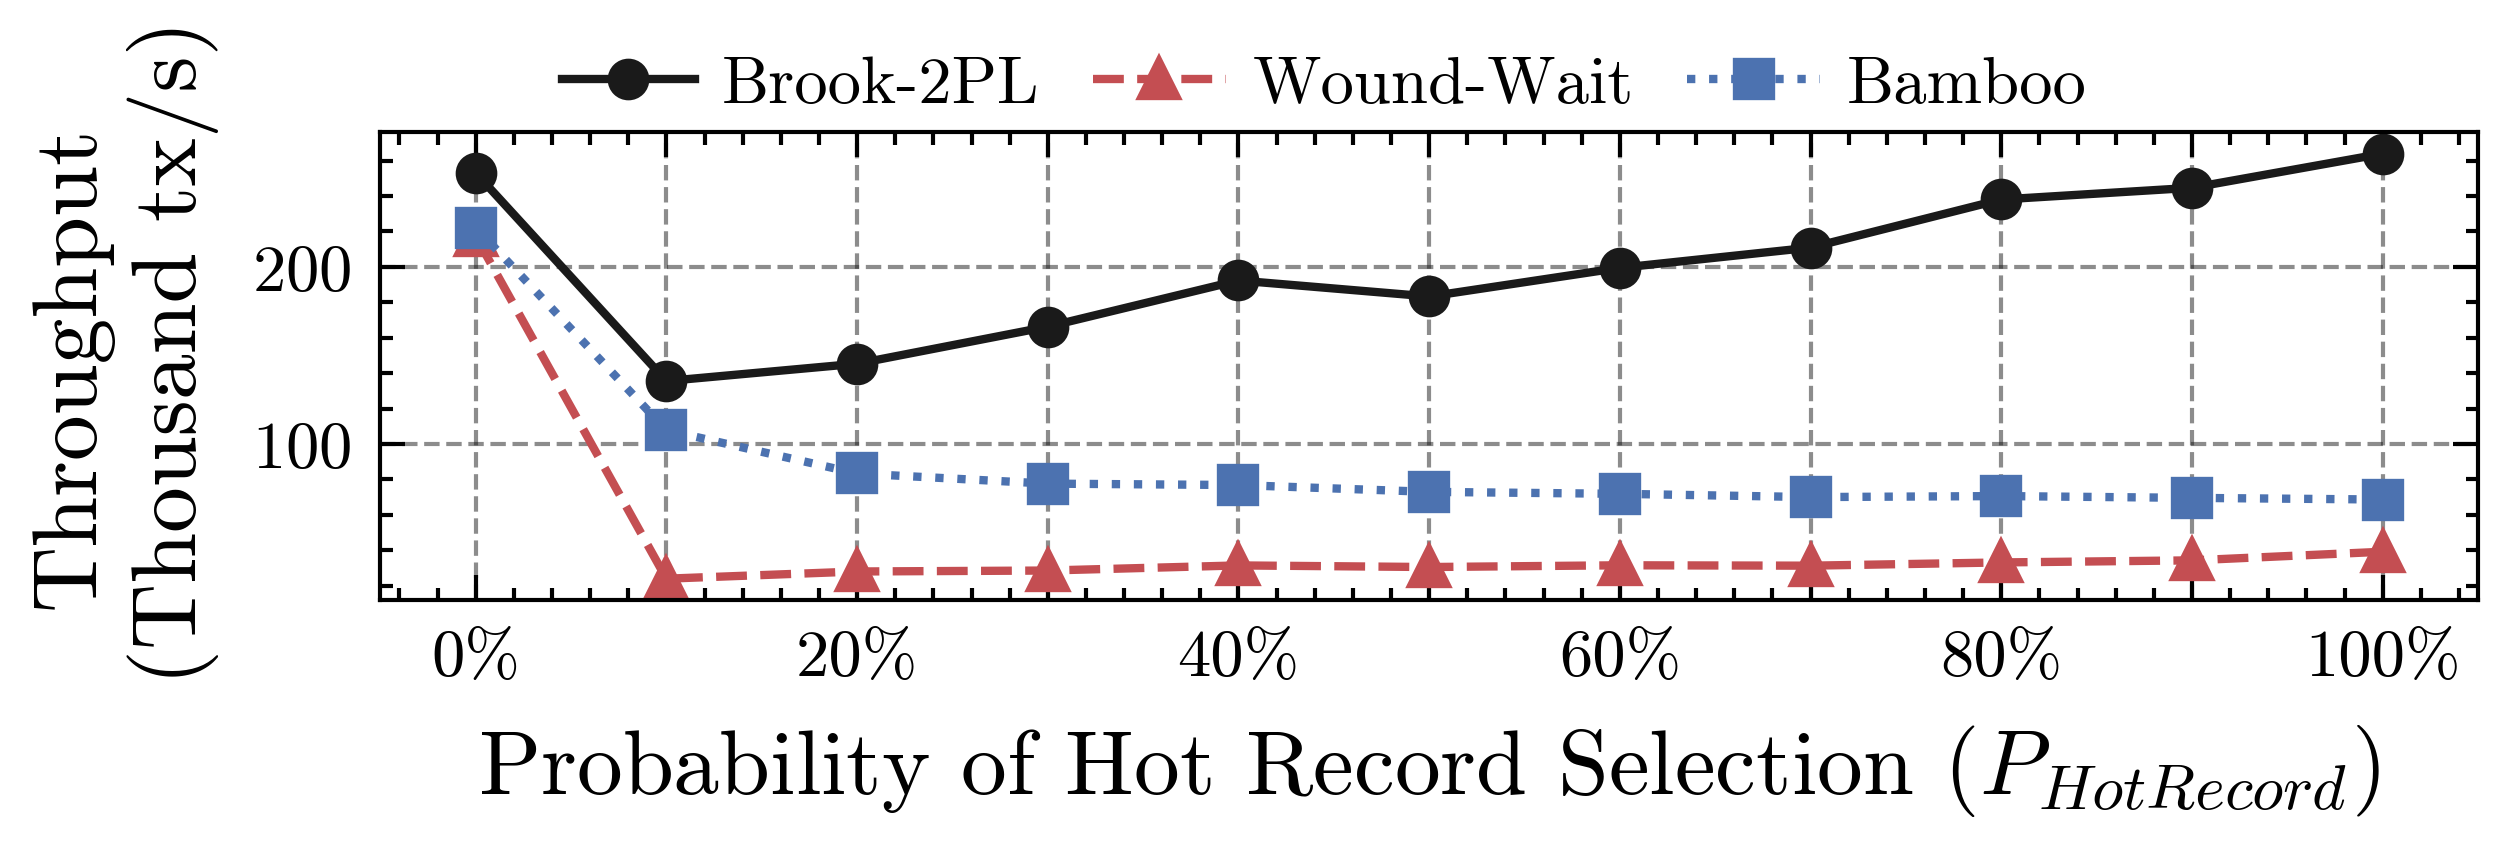

In [64]:
item_performance(20, 64)

# Interactive


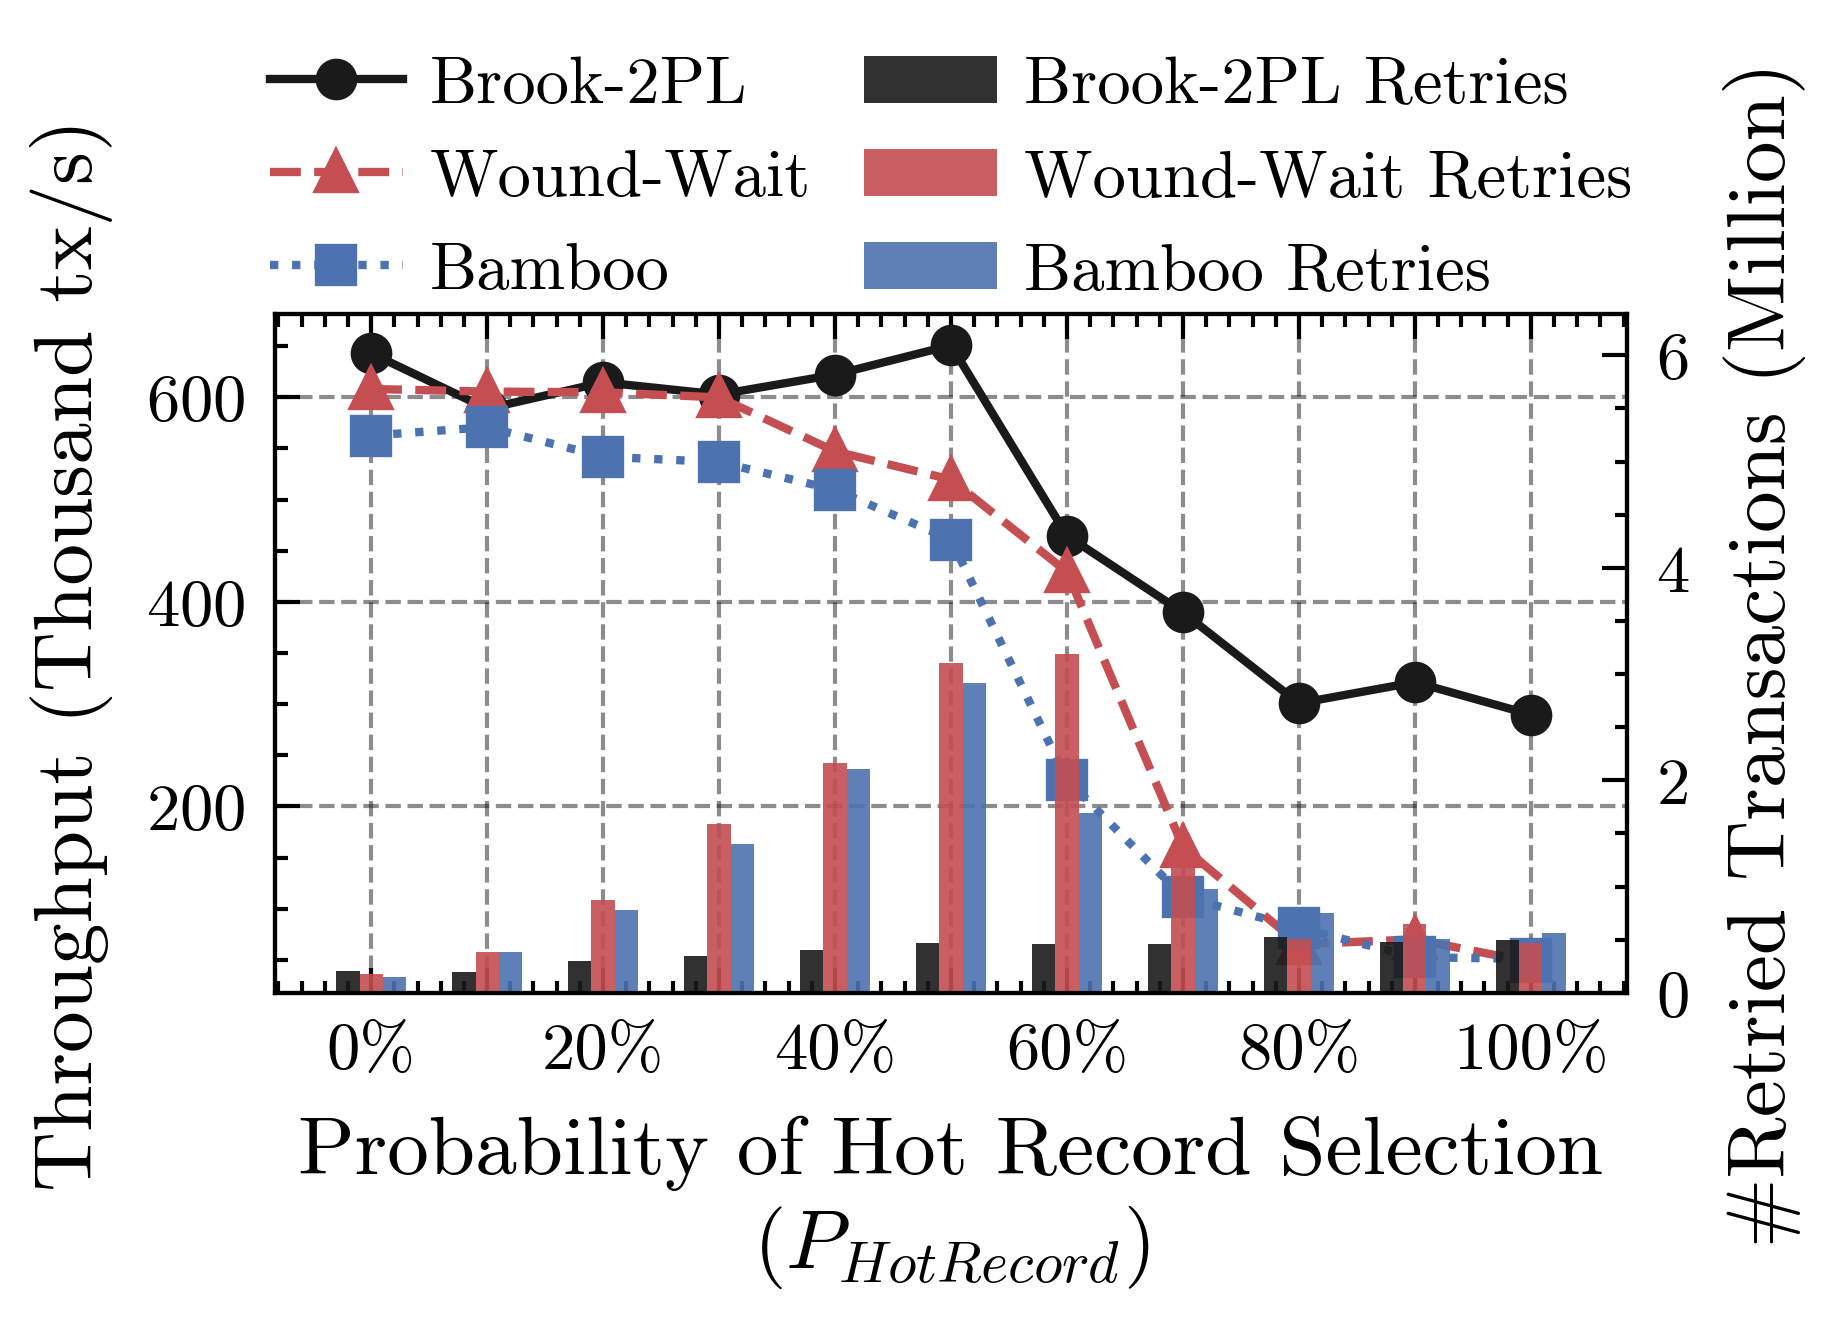

In [65]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Function to lighten a color
def lighten_color(color, amount=0.5):
    """
    Lighten the given color by blending it with white.
    amount=0 returns original color, amount=1 returns white.
    """
    try:
        c = mcolors.cnames[color]
    except:
        c = color
    c = mcolors.to_rgb(c)
    # Blend with white
    return ((1 - amount) * c[0] + amount, (1 - amount) * c[1] + amount, (1 - amount) * c[2] + amount)

# Load data
df = pd.read_csv('store-interactive.csv')

# Set up default colors from Matplotlib's cycle and map each mode to a color.
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
modes = ['slw', 'ww', 'bamboo']
custom_labels = {'slw': 'Brook-2PL', 'bamboo': 'Bamboo', 'ww': 'Wound-Wait'}

# Define a mapping for line colors (for throughput lines)
mode_colors = {
    'slw': default_colors[0],
    'ww': default_colors[1],
    'bamboo': default_colors[2] if len(default_colors) > 2 else default_colors[0]
}
# Define a mapping for bar colors by lightening the line colors slightly.
bar_colors = {mode: lighten_color(mode_colors[mode], amount=0) for mode in modes}

# Define markers for line plots
markers = {'slw': 'o', 'bamboo': 's', 'ww': '^'}

# Filter the DataFrame
filtered_df = df[(df['operation_delay'] == 0) & (df['interactive_size'] == 10)]

# Create figure and twin axes
fig, ax1 = plt.subplots(figsize=(3.2, 2.5))
ax2 = ax1.twinx()

# Bar plot parameters
bar_width = 2  # bar width in percentage points
offsets = {
    'slw': -bar_width,  # shift left
    'ww':  0.0,         # centered
    'bamboo': bar_width # shift right
}

# --- 1) Plot the bar plots (for request_retried) on ax2 first ---
for mode in modes:
    mode_data = filtered_df[filtered_df['mode'] == mode]
    ax2.bar(
        mode_data['prob'] + offsets[mode],
        mode_data['request_retried']/1000000,
        width=bar_width,
        alpha=0.9,  # increased opacity
        color=bar_colors[mode],
        label=f"{custom_labels[mode]} Retries",
        zorder=1
    )

# --- 2) Plot throughput lines (for throughput(tx/s)) on ax1 ---
for mode in modes:
    mode_data = filtered_df[filtered_df['mode'] == mode]
    ax1.plot(
        mode_data['prob'],
        mode_data['throughput(tx/s)'] / 1000,  # converting to thousand tx/s
        label=custom_labels[mode],
        marker=markers[mode],
        markersize=4,
        color=mode_colors[mode],
        zorder=2
    )

# --- 3) Axis labels and ticks ---
ax1.set_xlabel('Probability of Hot Record Selection\n($P_{HotRecord}$)', fontsize=10)
ax1.set_ylabel('Throughput (Thousand tx/s)', fontsize=10)
ax2.set_ylabel('#Retried Transactions (Million)', fontsize=10)

# Set x-ticks with percent labels
prob_ticks = range(0, 110, 10)
prob_labels = [f"{p}%" if p % 20 == 0 else "" for p in prob_ticks]
ax1.set_xticks(prob_ticks)
ax1.set_xticklabels(prob_labels)

# --- 4) Set y-limit for request retries to be 2 times the max value ---
max_retries = filtered_df['request_retried'].max()
ax2.set_ylim(0, 2 * max_retries/1000000)

# --- 5) Combine legends from both axes ---
lines1, labels1 = ax1.get_legend_handles_labels()
bars2, labels2 = ax2.get_legend_handles_labels()
all_lines = lines1 + bars2
all_labels = labels1 + labels2
ax1.legend(
    all_lines, all_labels,
    bbox_to_anchor=(0.5, 1.2),
    loc='center',
    ncol=2,
    frameon=False,
    fontsize=8,
    handletextpad=0.4,
    columnspacing=0.8
)
# ax1.grid(False)
ax2.grid(False)


# Removed grid lines
plt.tight_layout()
plt.savefig('performance_store_interactive_64.pdf', bbox_inches='tight')
plt.show()


In [66]:
# prompt: how much the average interactive(tx/s) of slw is better than bamboo and ww in times

import numpy as np
slw_throughput = filtered_df[filtered_df['mode'] == 'slw']['interactive(tx/s)']
bamboo_throughput = filtered_df[filtered_df['mode'] == 'bamboo']['interactive(tx/s)']
ww_throughput = filtered_df[filtered_df['mode'] == 'ww']['interactive(tx/s)']

avg_slw_throughput = np.mean(slw_throughput)
avg_bamboo_throughput = np.mean(bamboo_throughput)
avg_ww_throughput = np.mean(ww_throughput)

# Calculate improvements
improvement_bamboo = (avg_slw_throughput - avg_bamboo_throughput) / avg_bamboo_throughput * 100
improvement_ww = (avg_slw_throughput - avg_ww_throughput) / avg_ww_throughput * 100

print(f"SLW is {improvement_bamboo:.2f}% better than Bamboo on average.")
print(f"SLW is {improvement_ww:.2f}% better than WW on average.")


SLW is 79.55% better than Bamboo on average.
SLW is 56.05% better than WW on average.


In [67]:
# prompt: how much the average interactive(tx/s) of slw is better than bamboo and ww in times

import numpy as np
slw_throughput = filtered_df[filtered_df['mode'] == 'slw']['throughput(tx/s)'] -  filtered_df[filtered_df['mode'] == 'slw']['interactive(tx/s)']
bamboo_throughput =  filtered_df[filtered_df['mode'] == 'bamboo']['throughput(tx/s)'] - filtered_df[filtered_df['mode'] == 'bamboo']['interactive(tx/s)']
ww_throughput = filtered_df[filtered_df['mode'] == 'ww']['throughput(tx/s)'] - filtered_df[filtered_df['mode'] == 'ww']['interactive(tx/s)']

avg_slw_throughput = np.mean(slw_throughput)
avg_bamboo_throughput = np.mean(bamboo_throughput)
avg_ww_throughput = np.mean(ww_throughput)

# Calculate improvements
improvement_bamboo = (avg_slw_throughput - avg_bamboo_throughput) / avg_bamboo_throughput * 100
improvement_ww = (avg_slw_throughput - avg_ww_throughput) / avg_ww_throughput * 100

print(f"SLW is {improvement_bamboo:.2f}% better than Bamboo on average.")
print(f"SLW is {improvement_ww:.2f}% better than WW on average.")


SLW is 46.46% better than Bamboo on average.
SLW is 27.45% better than WW on average.


# TPCC

In [68]:
df = pd.read_csv('tpcc-results.csv')

## TPCC based on number of warehouses

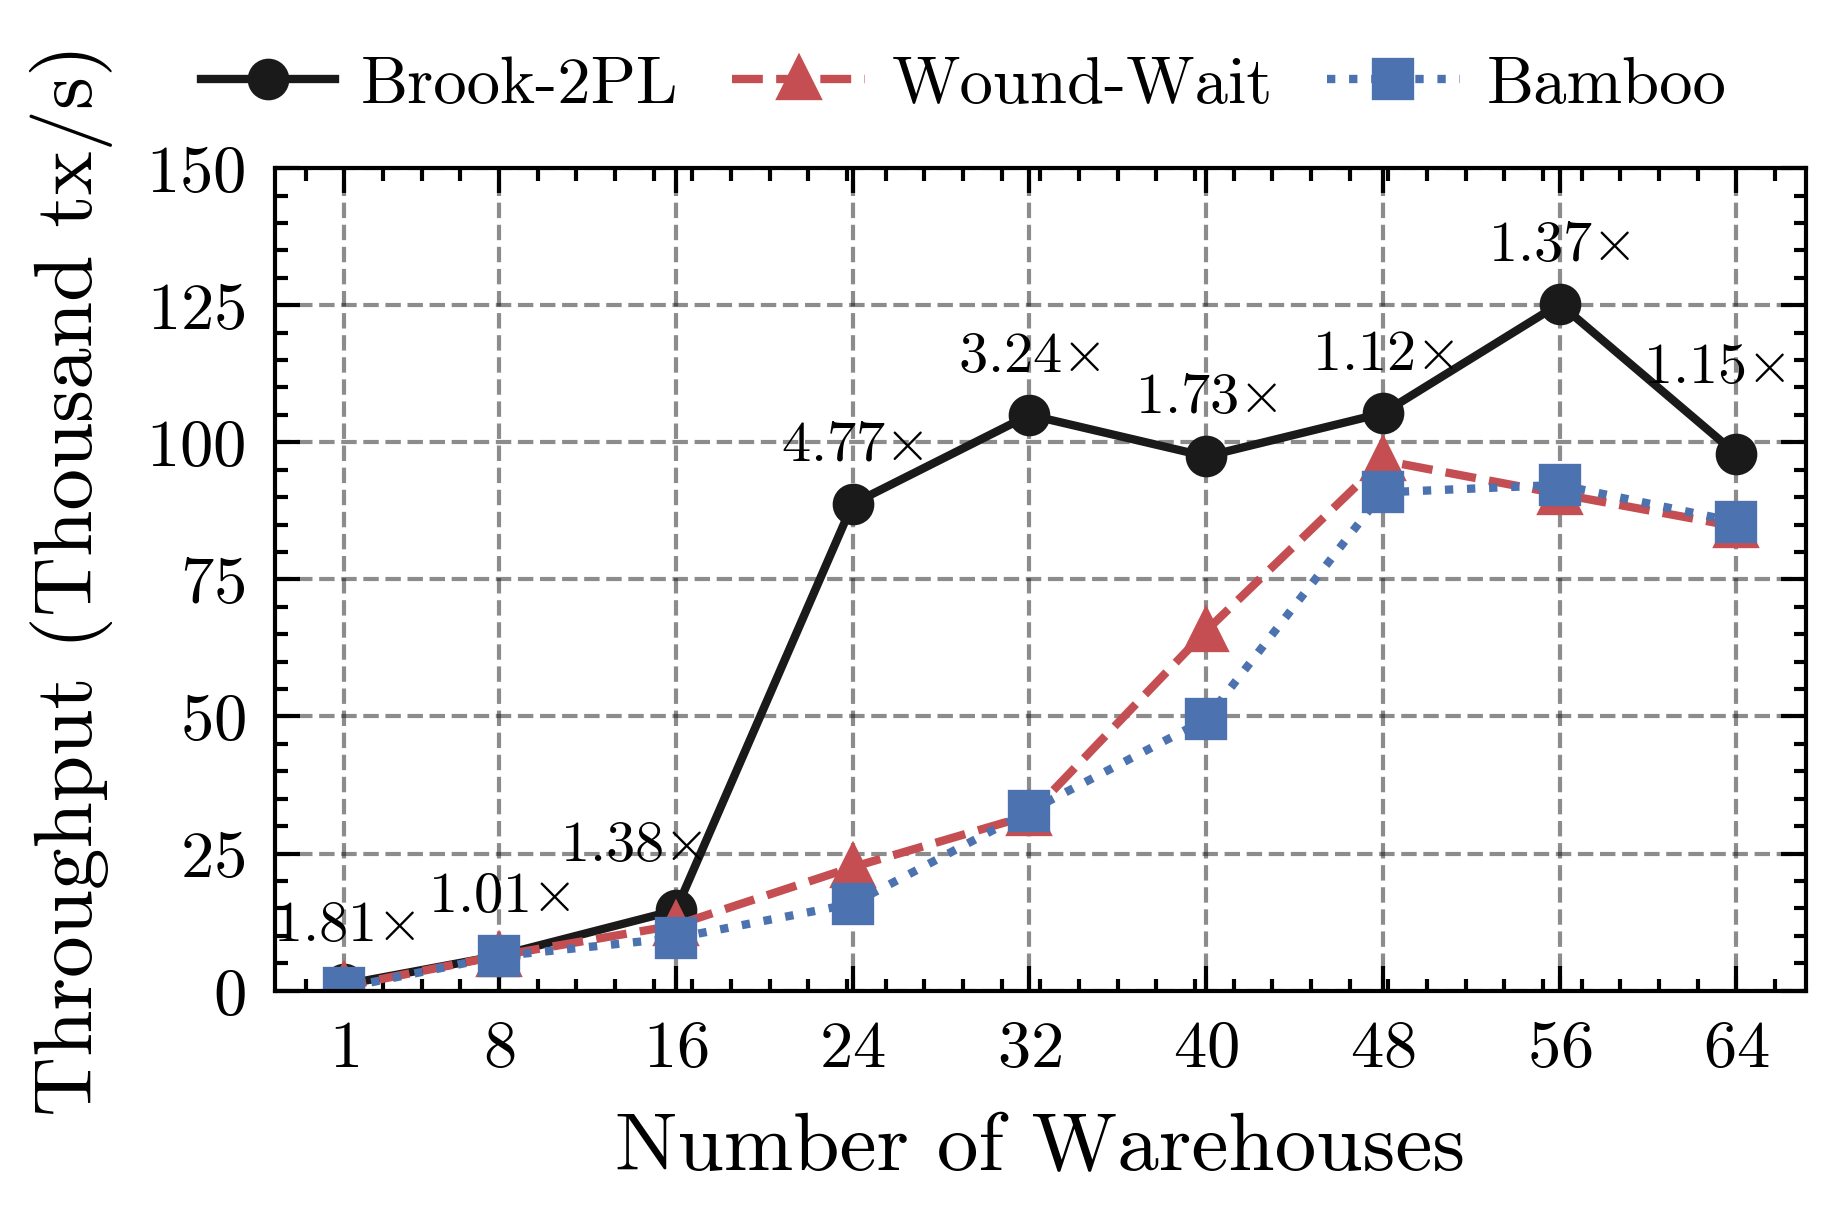

In [69]:
# plt.figure(figsize=(4.32, 1.8))
plt.figure(figsize=(3.2, 2.2))

df['warehouse'] = df['warehouse'].astype(int)
markers = {
    'slw': 'o',        # Circle for SLW-Graph
    'bamboo': 's',     # Square for Bamboo
    'ww': '^'          # Triangle for Wound-Wait
}

# Plot each mode separately
for mode in ['slw', 'ww', 'bamboo']:
    mode_data = df[df['operation_delay'] == 0][df['mode'] == mode]
    plt.plot(
        mode_data['warehouse'],
        mode_data['throughput(tx/s)'] / 1000,
        label=mode,
        marker=markers[mode],
        markersize=4
    )
    if mode == 'slw':
        speedupWW = (np.array(mode_data['throughput(tx/s)']) /
                     np.array(df[df['operation_delay'] == 0][df['mode'] == 'ww']['throughput(tx/s)']))
        speedupBamboo = (np.array(mode_data['throughput(tx/s)']) /
                         np.array(df[df['operation_delay'] == 0][df['mode'] == 'bamboo']['throughput(tx/s)']))
        avg = (speedupWW + speedupBamboo) / 2
        for i in range(len(mode_data['throughput(tx/s)'])):
          j,z = 0,0
          if i == 0:
            j, z = -1,5
          elif i == 6:
            j, z= -2, 1
          plt.annotate(f'${avg[i]:.2f}$' + r'$ \times $',
                         (np.array(mode_data['warehouse'])[i] + j,
                          np.array(mode_data['throughput(tx/s)'])[i] / 1000 + 8 + z),
                         ha='center', fontweight='bold', fontsize=7)

plt.xlabel('Number of Warehouses', fontsize=10)
plt.ylabel('Throughput (Thousand tx/s)', fontsize=10)

# Custom legend labels
custom_labels = {'slw': 'Brook-2PL', 'bamboo': 'Bamboo', 'ww': 'Wound-Wait'}
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [custom_labels[label] for label in labels if label in custom_labels]
# plt.legend(handles, new_labels, fontsize=7, loc='lower right')

plt.legend(
    handles, new_labels,
    bbox_to_anchor=(0.45, 1.1),  # Position above the plot
    loc='center',                # Center-align
    ncol=len(handles),           # Single-line legend
    frameon=False ,               # Optional: Remove legend border
      handletextpad=0.4,           # Reduce space between handles and text
    columnspacing=0.8,          # Reduce space between legend columns,
    fontsize=8
)

plt.grid(True)

# Set the y-axis limits to 0-150 and specify custom x-axis ticks.
plt.ylim(0, 150)
plt.xticks([64, 56, 48, 40, 32, 24, 16, 8, 1])

plt.tight_layout()
plt.savefig('performance_tpcc_varyingWarehouse.pdf', bbox_inches='tight')


## TPCC Prob

In [70]:
df = pd.read_csv('tpcc-prob.csv')

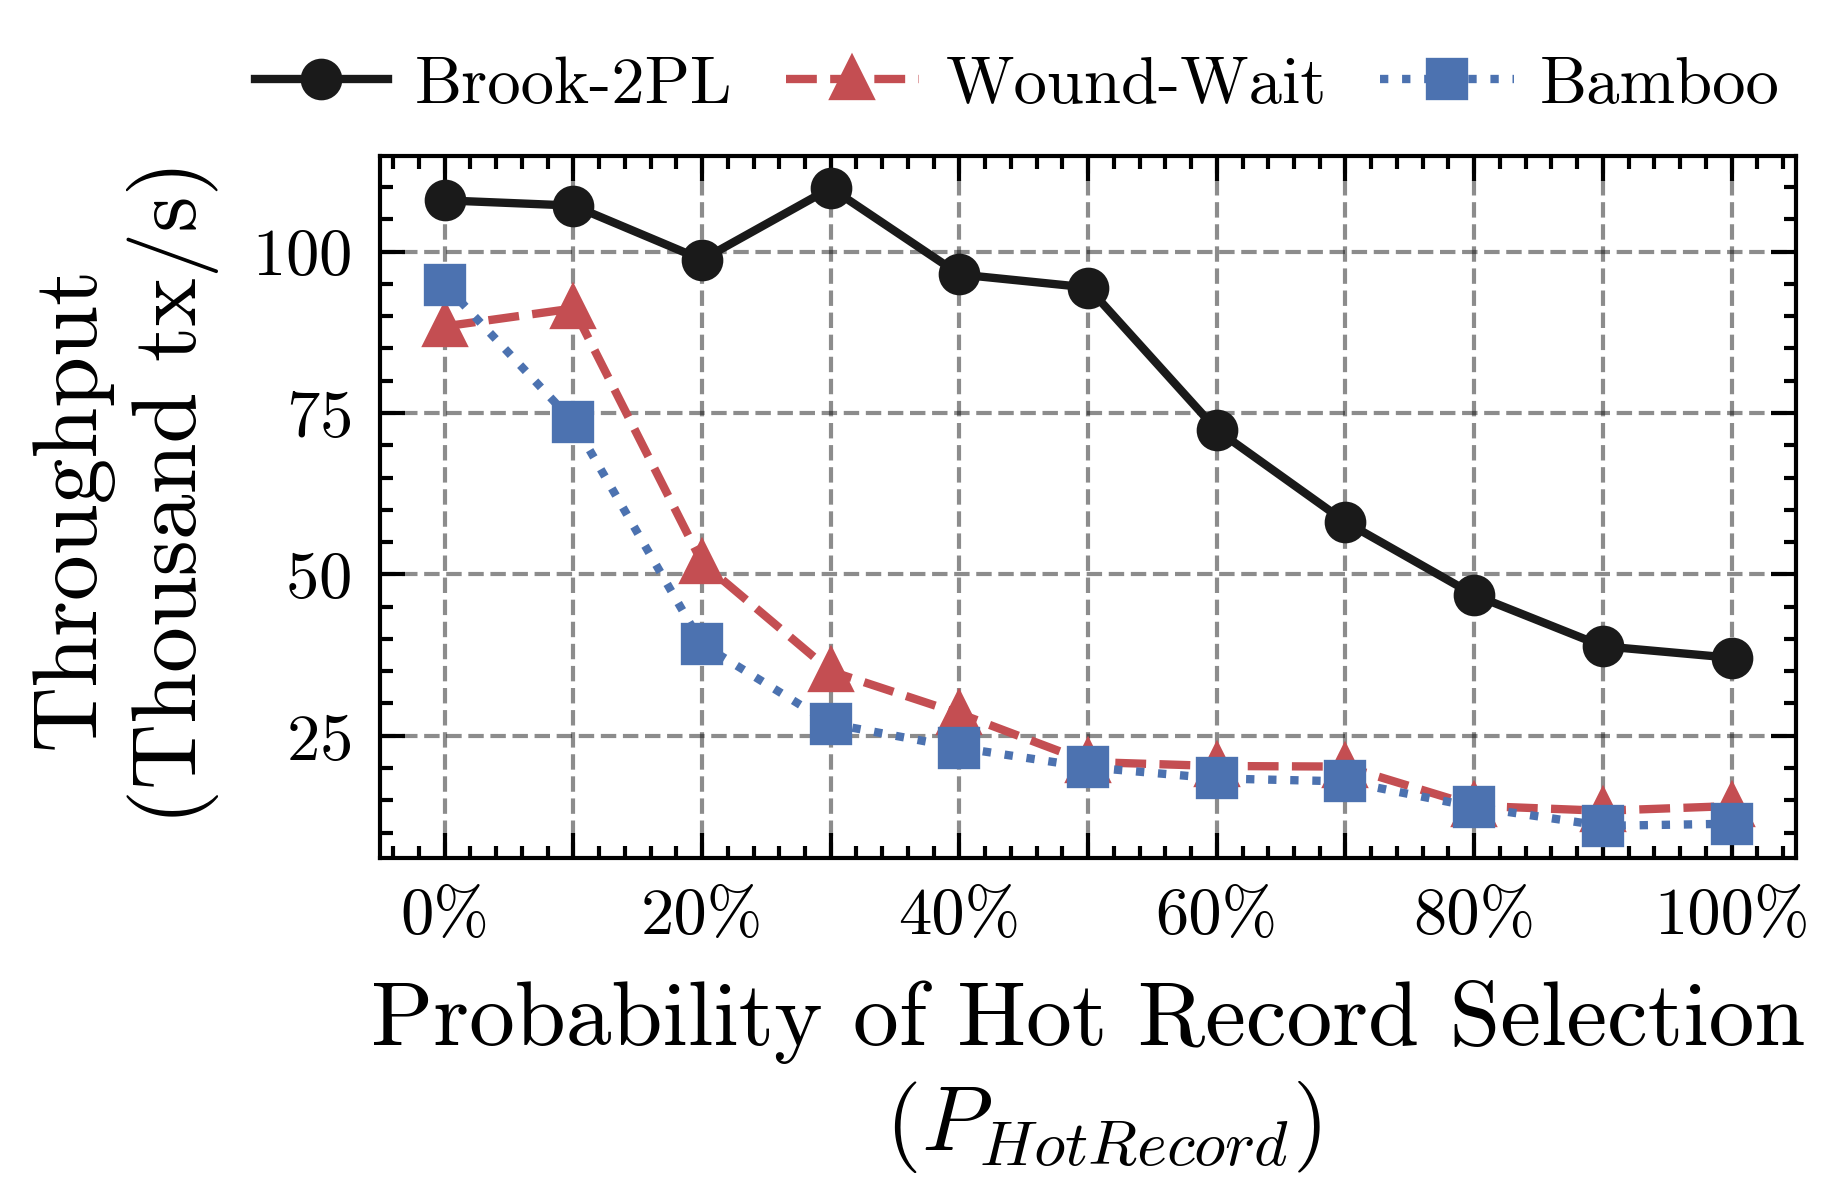

In [71]:
# Get Matplotlib's default color cycle
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Map each hotness level to a specific color from the color cycle
hotness_color_map = {hotness: color for hotness, color in zip(pd.unique(df['hot_records']), colors)}
markers = {
    'slw': 'o',        # Circle for SLW-Graph
    'bamboo': 's',     # Square for Bamboo
    'ww': '^'          # Triangle for Wound-Wait
}

# Determine the number of unique delays
unique_delays = sorted(pd.unique(df['operation_delay']))
num_delays = len(unique_delays)


plt.figure(figsize=(3.2, 2.2))

filtered_df = df[(df['operation_delay'] == 0)]
# filtered_df = filtered_df[filtered_df['hot_records'] == '../rocksdb/hotspots/hot_records_32_items']

# Plot each mode separately
for mode in ['slw', 'ww', 'bamboo']:
    mode_data = filtered_df[filtered_df['mode'] == mode]
    plt.plot(
        mode_data['prob'],
        mode_data['throughput(tx/s)']/1000,
        label=mode,  # Add the mode to the legend
        # marker = True,
        marker=markers[mode],
        # linestyle='-',  # Solid line
        # linewidth=1.5,
        markersize=4
    )


# plt.title(f'Performance for TPC-C')
plt.xlabel('Probability of Hot Record Selection\n ($P_{HotRecord}$)', fontsize=11)
plt.ylabel('Throughput\n (Thousand tx/s)', fontsize=11)

# ticks with percent
prob = range(0, 110, 10)
prob_str = [str(prob[i]) + "%" if prob[i] % 20 == 0 else "" for i in range(0, len(prob))]
plt.xticks(prob, labels=prob_str)

# Custom legend labels
custom_labels = {'slw': 'Brook-2PL', 'bamboo': 'Bamboo', 'ww': 'Wound-Wait'}
handles, labels = plt.gca().get_legend_handles_labels()
new_labels = [custom_labels[label] for label in labels if label in custom_labels]
# plt.legend(handles, new_labels)

# ax.legend(handles, labels,  bbox_to_anchor=(1, 1), loc='upper left')
plt.legend(
    handles, new_labels,
    bbox_to_anchor=(0.45, 1.1),  # Position above the plot
    loc='center',                # Center-align
    ncol=len(handles),           # Single-line legend
    frameon=False ,               # Optional: Remove legend border
      handletextpad=0.4,           # Reduce space between handles and text
    columnspacing=0.8,          # Reduce space between legend columns,
    fontsize=8
)


plt.grid(True)



plt.tight_layout()
plt.plot()
plt.savefig('performance_tpcc_varyingProb_16.pdf', bbox_inches='tight')

In [72]:

speedupWW = np.array(filtered_df[filtered_df['mode'] == 'slw']['throughput(tx/s)']) / np.array(filtered_df[filtered_df['mode'] == 'ww']['throughput(tx/s)'])
speedupBamboo = np.array(filtered_df[filtered_df['mode'] == 'slw']['throughput(tx/s)']) / np.array(filtered_df[filtered_df['mode'] == 'bamboo']['throughput(tx/s)'])
avg = (speedupWW + speedupBamboo) / 2
avg.mean()

np.float64(2.999824198725703)

In [73]:
(np.array(filtered_df[filtered_df['mode'] == 'slw']['throughput(tx/s)']) / np.array(filtered_df[filtered_df['mode'] == 'ww']['throughput(tx/s)'])).mean()

np.float64(2.783707220729597)

In [74]:
(np.array(filtered_df[filtered_df['mode'] == 'slw']['throughput(tx/s)']) / np.array(filtered_df[filtered_df['mode'] == 'bamboo']['throughput(tx/s)'])).mean()

np.float64(3.2159411767218073)

## TPCC Latency

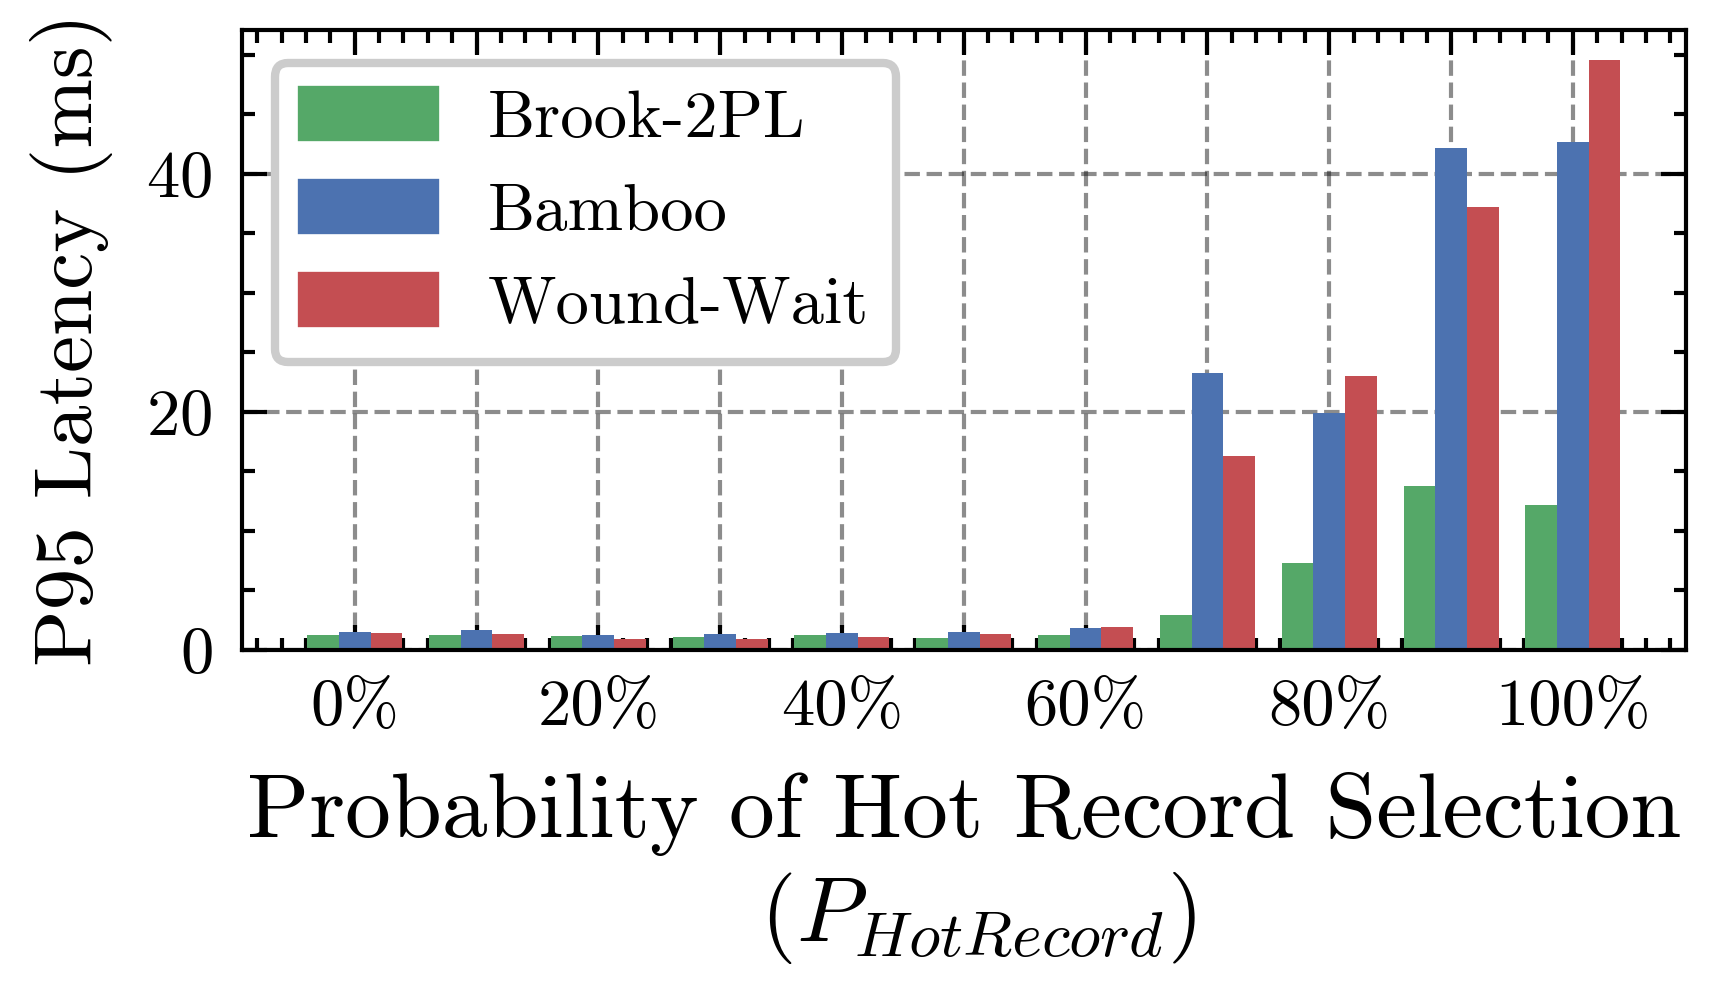

In [75]:
df = pd.read_csv('tpcc-prob.csv')
# def b_plot(col='throughput(tx/s)', col_name='Throughput (tx/s)'):
col='95th_latency'
# Get Matplotlib's default color cycle
colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

# Assign colors from the default color cycle to the methods
method_colors = {
    'slw': colors[3],        # First color for SLW-Graph
    'ww': colors[1],     # Second color for Bamboo
    'bamboo': colors[2]          # Third color for Wound-Wait
}

# Determine the number of unique delays and hotness levels
unique_delays = sorted(pd.unique(df['operation_delay']))
unique_hotness = pd.unique(df['hot_records'])
num_delays = 1
num_hotness = 1

plt.figure(figsize=(3, 1.8))
# Width of the bars
bar_width = 0.26


# Custom legend for methods
method_legend = [
    mpatches.Patch(color=method_colors['slw'], label='Brook-2PL'),
    mpatches.Patch(color=method_colors['bamboo'], label='Bamboo'),
    mpatches.Patch(color=method_colors['ww'], label='Wound-Wait')
]

# Iterate over each operation delay
i = 0
j = 0
delay = 0
hotness = '../rocksdb/hotspots/hot_records_32_items'
#   # Iterate over each operation delay
# for i, delay in enumerate(unique_delays):
#     # Iterate over each hotness level
#     for j, hotness in enumerate(unique_hotness):
#       # Iterate over each hotness level
# for j, hotness in enumerate(unique_hotness):
# ax = axes[i][j]
filtered_df = df[(df['operation_delay'] == delay)]
prob = range(0, 110, 10)
# Positioning bars
indices = np.arange(len(prob))

# Bar plots for each mode with specific colors
plt.bar(indices, np.array(filtered_df[filtered_df['mode'] == 'slw'][col])/1000, width=bar_width, label='SLW-Graph', color=method_colors['slw'])
plt.bar(indices + 2 * bar_width,  np.array(filtered_df[filtered_df['mode'] == 'ww'][col])/1000, width=bar_width, label='Wound-Wait', color=method_colors['ww'])
plt.bar(indices + bar_width, np.array(filtered_df[filtered_df['mode'] == 'bamboo'][col])/1000, width=bar_width, label='Bamboo', color=method_colors['bamboo'])



# plt.title('Latency for TPC-C Workload')
plt.xlabel('Probability of Hot Record Selection\n ($P_{HotRecord}$)', fontsize=11)
plt.ylabel('P95 Latency (ms)', fontsize=10)
plt.grid(True)

# Adjusting x-ticks to show properly in the center of grouped bars
prob = range(0, 110, 10)
prob_str = [str(prob[i]) + "%" if prob[i] % 20 == 0 else "" for i in range(0, len(prob))]

plt.xticks(indices + bar_width, labels=prob_str)

# plt.xticklabels(prob)

# Ensure all axes show numbers
# ax.tick_params(axis='both', which='both', labelsize=10)
plt.legend(handles=method_legend)


  # Add a global legend outside the subplots
  # fig.legend(handles=method_legend, loc='upper center', ncol=num_hotness, bbox_to_anchor=(0.5, 1.05))

plt.tight_layout()
plt.plot()
plt.savefig('latency_tpcc_varingProb_16.pdf', bbox_inches='tight')
plt.show()

In [76]:
slw_latency, ww_latency, bamboo_latency = filtered_df[filtered_df['mode'] == 'slw']['95th_latency'], filtered_df[filtered_df['mode'] == 'ww']['95th_latency'], filtered_df[filtered_df['mode'] == 'bamboo']['95th_latency']

In [77]:
((np.array(ww_latency) - np.array(slw_latency)) / np.array(ww_latency) * 100).mean()

np.float64(27.545054356748064)

In [78]:
((np.array(bamboo_latency) - np.array(slw_latency)) / np.array(bamboo_latency) * 100).mean()

np.float64(39.11503825157789)

In [79]:
((1 - (np.array(filtered_df[filtered_df['mode'] == 'ww']['avg_latency']) - np.array(filtered_df[filtered_df['mode'] == 'ww']['avg_latency']))) * 100).max()

np.float64(100.0)

## Useful work

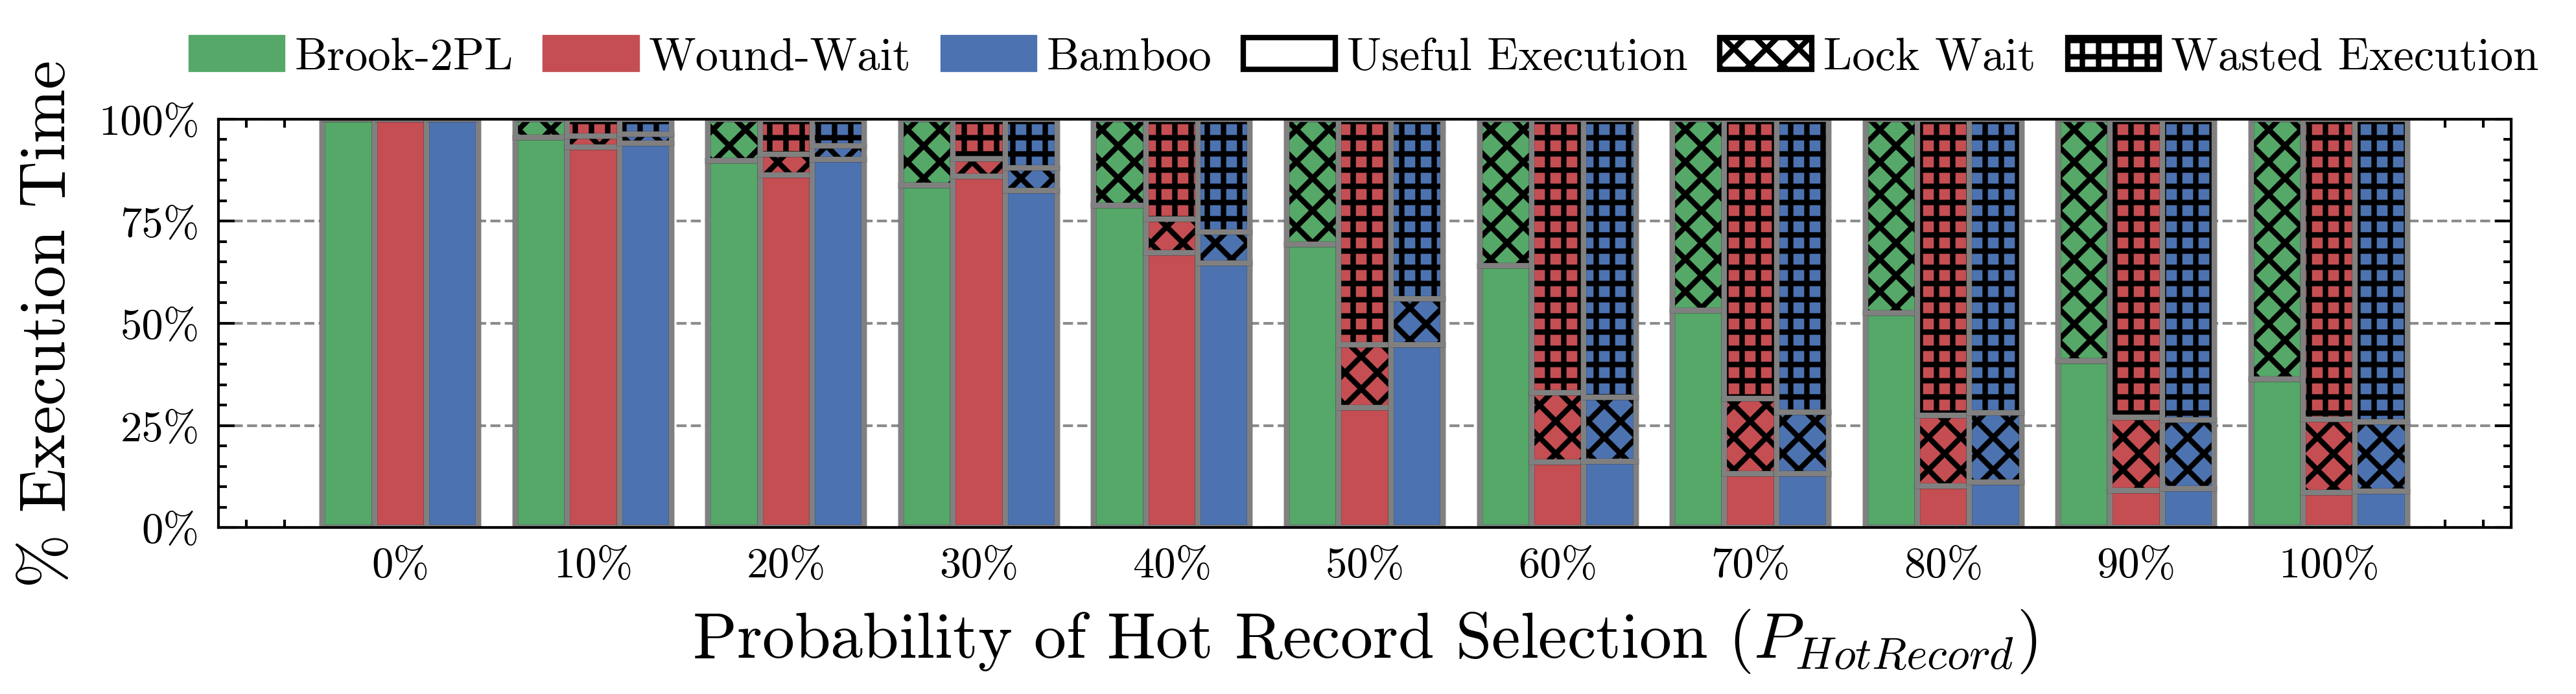

In [80]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches
import matplotlib.ticker as mtick  # Import ticker for percentage formatting

df = pd.read_csv('store-results.csv')
colorss = plt.rcParams['axes.prop_cycle'].by_key()['color']
df_norm = df[df['operation_delay'] == 0].copy()
df_norm = df_norm[df_norm['hot_records'] == '../rocksdb/hotspots/hot_records_64_items']
df_norm['total_time'] = df_norm[['useful_time', 'waited_time', 'wasted_time']].sum(axis=1)
df_norm['useful_time'] = df_norm['useful_time'] / df_norm['total_time']
df_norm['waited_time'] = df_norm['waited_time'] / df_norm['total_time']
df_norm['wasted_time'] = df_norm['wasted_time'] / df_norm['total_time']

# Pivot the data to structure it for grouped stacked bars
df_pivot = df_norm.pivot(index='prob', columns='mode', values=['useful_time', 'waited_time', 'wasted_time'])

# Create an array of positions for the x-ticks
n_modes = len(df['mode'].unique())
width = 0.27  # Width of each bar group
x = np.arange(len(df_pivot.index))  # The label locations

# Define different colors for each mode
colors = [colorss[3], colorss[1], colorss[2]]

# Define hatches for different stack layers
hatches = ['', 'xxxx', '++++']

# Plot each stacked bar for each mode with a larger figure size
fig, ax = plt.subplots(figsize=(7, 2))

for i, (mode, color) in enumerate(zip(['slw', 'ww', 'bamboo'], colors)):
    bottom = np.zeros(len(df_pivot))
    for j, (work_type, hatch) in enumerate(zip(['useful_time', 'waited_time', 'wasted_time'], hatches)):
        ax.bar(x + i * width, df_pivot[(work_type, mode)], width,
               label=f'{work_type}_{mode}' if j == 0 else "",
               color=color, hatch=hatch, bottom=bottom, edgecolor="black")
        ax.bar(x + i * width, df_pivot[(work_type, mode)], width,
               label=f'{work_type}_{mode}' if j == 0 else "",
               color='none', bottom=bottom, edgecolor="gray")
        bottom += df_pivot[(work_type, mode)].values

# Create custom legend
# Mode legend (colors)
mode_handles = [plt.Rectangle((0,0),1,1, color=color) for color in colors]
mode_labels = ['Brook-2PL', 'Wound-Wait', 'Bamboo']

# Work type legend (hatches)
work_handles = [mpatches.Patch(facecolor='white', edgecolor='black', hatch=hatch, label='Label1') for hatch in hatches]
work_labels = ['Useful Execution', 'Lock Wait', 'Wasted Execution']

# Customize the plot
ax.set_xlabel('Probability of Hot Record Selection ($P_{HotRecord}$)', fontsize=12)
ax.set_ylabel('% Execution Time', fontsize=12)
ax.set_xticks(x + width * (n_modes - 1) / 2)
prob = range(0, 110, 10)
prob_str = [f"{p}%" for p in prob]
ax.set_xticklabels(prob_str)

# Set y-axis formatter to display percentages
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))

# Combine mode and work handles and labels for the legend
handles = mode_handles + work_handles
labels = mode_labels + work_labels
ax.legend(handles, labels,
          bbox_to_anchor=(0.5, 1.15),  # Position above the plot
          loc='center',
          ncol=len(handles),           # Single-line legend
          frameon=False,               # Remove legend border
          handletextpad=0.25,           # Reduce space between handles and text
          columnspacing=0.7,           # Reduce space between legend columns
          fontsize=8.5)

plt.tight_layout()
plt.savefig('workPorportion_sotre_64.pdf', bbox_inches='tight')


In [81]:
# prompt: Using dataframe df_pivot: calculate the average usefull work for each method

# Calculate the average useful work for each method
average_useful_work = df_pivot[[('useful_time', 'bamboo'), ('useful_time', 'slw'), ('useful_time', 'ww')]].mean()

# Print the results
average_useful_work


mode  
useful_time  bamboo    0.486423
             slw       0.694953
             ww        0.471952
dtype: float64

## Interactive

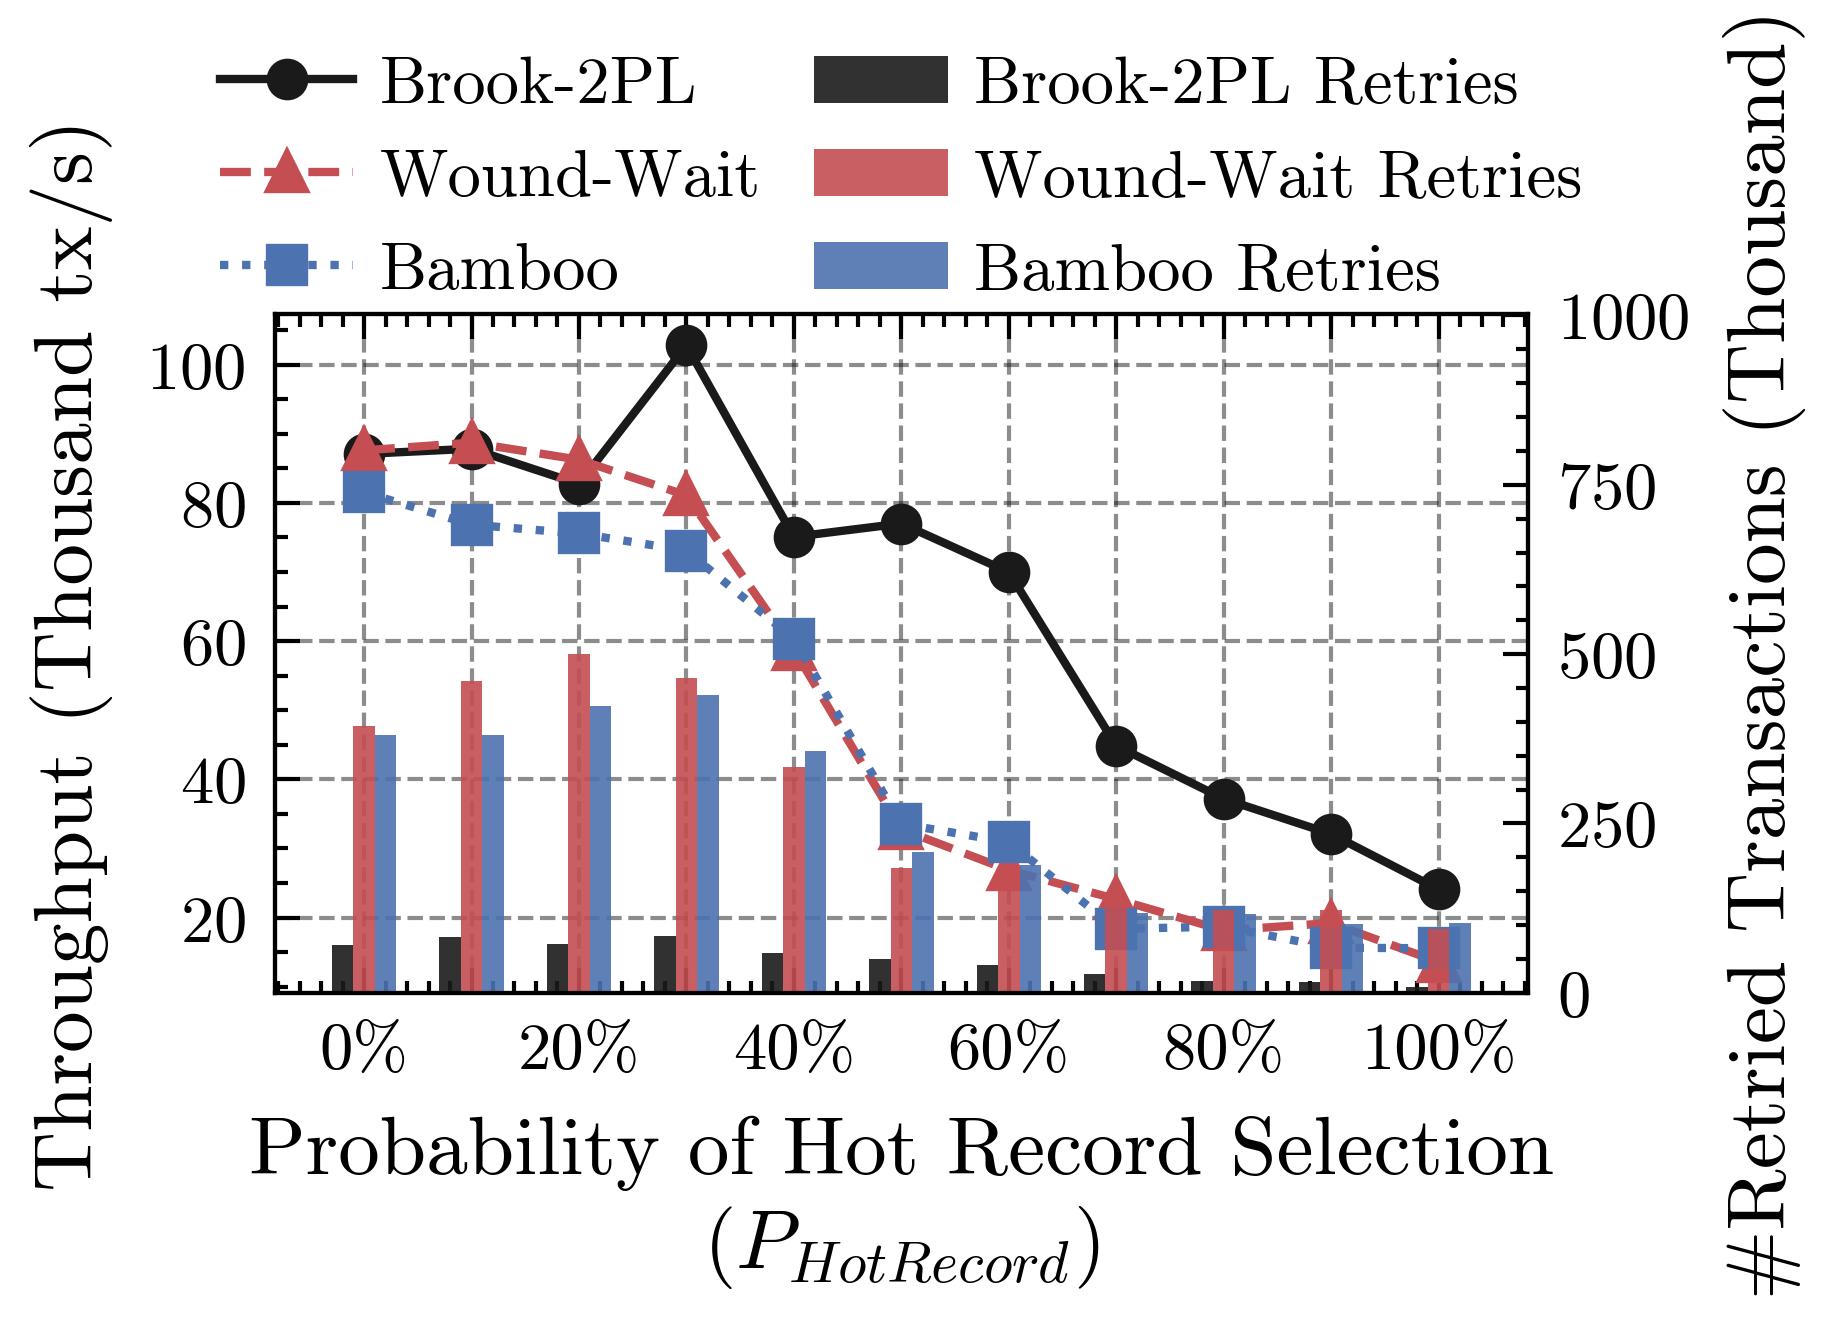

In [82]:


import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

# Function to lighten a color
def lighten_color(color, amount=0):
    """
    Lighten the given color by blending it with white.
    amount=0 returns original color, amount=1 returns white.
    """
    try:
        c = mcolors.cnames[color]
    except:
        c = color
    c = mcolors.to_rgb(c)
    # Blend with white
    return ((1 - amount) * c[0] + amount, (1 - amount) * c[1] + amount, (1 - amount) * c[2] + amount)

# Load data
df = pd.read_csv('tpcc-interactive.csv')

# Set up default colors from Matplotlib's cycle and map each mode to a color.
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
modes = ['slw', 'ww', 'bamboo']
custom_labels = {'slw': 'Brook-2PL', 'bamboo': 'Bamboo', 'ww': 'Wound-Wait'}

# Define a mapping for line colors (for throughput lines)
mode_colors = {
    'slw': default_colors[0],
    'ww': default_colors[1],
    'bamboo': default_colors[2] if len(default_colors) > 2 else default_colors[0]
}
# Define a mapping for bar colors by lightening the line colors slightly.
bar_colors = {mode: lighten_color(mode_colors[mode], amount=0) for mode in modes}

# Define markers for line plots
markers = {'slw': 'o', 'bamboo': 's', 'ww': '^'}

# Filter the DataFrame
filtered_df = df[(df['operation_delay'] == 0) & (df['interactive_size'] == 10)]

# Create figure and twin axes
fig, ax1 = plt.subplots(figsize=(3.2, 2.5))
ax2 = ax1.twinx()

# Bar plot parameters
bar_width = 2  # bar width in percentage points
offsets = {
    'slw': -bar_width,  # shift left
    'ww':  0.0,         # centered
    'bamboo': bar_width # shift right
}

# --- 1) Plot the bar plots (for request_retried) on ax2 first ---
for mode in modes:
    mode_data = filtered_df[filtered_df['mode'] == mode]
    ax2.bar(
        mode_data['prob'] + offsets[mode],
        mode_data['request_retried']/1000,
        width=bar_width,
        alpha=0.9,  # increased opacity
        color=bar_colors[mode],
        label=f"{custom_labels[mode]} Retries",
        zorder=1
    )

# --- 2) Plot throughput lines (for throughput(tx/s)) on ax1 ---
for mode in modes:
    mode_data = filtered_df[filtered_df['mode'] == mode]
    ax1.plot(
        mode_data['prob'],
        mode_data['throughput(tx/s)'] / 1000,  # converting to thousand tx/s
        label=custom_labels[mode],
        marker=markers[mode],
        markersize=4,
        color=mode_colors[mode],
        zorder=2
    )

# --- 3) Axis labels and ticks ---
ax1.set_xlabel('Probability of Hot Record Selection\n($P_{HotRecord}$)', fontsize=10)
ax1.set_ylabel('Throughput (Thousand tx/s)', fontsize=10)
ax2.set_ylabel('#Retried Transactions (Thousand)', fontsize=10)

# Set x-ticks with percent labels
prob_ticks = range(0, 110, 10)
prob_labels = [f"{p}%" if p % 20 == 0 else "" for p in prob_ticks]
ax1.set_xticks(prob_ticks)
ax1.set_xticklabels(prob_labels)

# --- 4) Set y-limit for request retries to be 2 times the max value ---
max_retries = filtered_df['request_retried'].max()
ax2.set_ylim(0, 2 * max_retries/1000)

# --- 5) Combine legends from both axes ---
lines1, labels1 = ax1.get_legend_handles_labels()
bars2, labels2 = ax2.get_legend_handles_labels()
all_lines = lines1 + bars2
all_labels = labels1 + labels2
ax1.legend(
    all_lines, all_labels,
    bbox_to_anchor=(0.5, 1.2),
    loc='center',
    ncol=2,
    frameon=False,
    fontsize=8,
    handletextpad=0.4,
    columnspacing=0.8
)
# ax1.grid(False)
ax2.grid(False)

# Removed grid lines
plt.tight_layout()
plt.savefig('performance_tpcc_interactive_16.pdf', bbox_inches='tight')
plt.show()


In [83]:
# prompt: download all the files in /content in a zip

!zip -r /content/content.zip /content


  adding: content/ (stored 0%)
  adding: content/.config/ (stored 0%)
  adding: content/.config/active_config (stored 0%)
  adding: content/.config/logs/ (stored 0%)
  adding: content/.config/logs/2025.04.09/ (stored 0%)
  adding: content/.config/logs/2025.04.09/13.37.51.026068.log (deflated 58%)
  adding: content/.config/logs/2025.04.09/13.37.59.170421.log (deflated 86%)
  adding: content/.config/logs/2025.04.09/13.38.00.354311.log (deflated 58%)
  adding: content/.config/logs/2025.04.09/13.38.09.438379.log (deflated 56%)
  adding: content/.config/logs/2025.04.09/13.37.30.549742.log (deflated 93%)
  adding: content/.config/logs/2025.04.09/13.38.08.751788.log (deflated 57%)
  adding: content/.config/.last_survey_prompt.yaml (stored 0%)
  adding: content/.config/gce (stored 0%)
  adding: content/.config/.last_opt_in_prompt.yaml (stored 0%)
  adding: content/.config/.last_update_check.json (deflated 22%)
  adding: content/.config/hidden_gcloud_config_universe_descriptor_data_cache_config